# MethSCAn downstream clustering analysis on VMR matrix before variant masking

In [3]:
import scanpy as sc
import anndata as ad
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import gzip
import os
import subprocess
from scipy import io
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.filterwarnings(action="ignore", category=UserWarning)

%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import sys
sys.path.append('/data/leuven/357/vsc35706/notebook/sciMET/sciMET_PBMC/utils')
from utils import *

sns.set_context(context='notebook', font_scale=1)
wd = "/staging/leuven/stg_00064/Xinran/project/sciMET_PBMC/260120_BC_methscan"
os.chdir(wd)

# Set plotting parameters
plt.rcParams['figure.dpi'] = 150
plt.rcParams['figure.figsize'] = (2,2)
dotsize=3
alpha=0.8
context = 'ori_VMR.incl_doub.before_debias'

## Load prepared h5ad from methscan output

In [3]:
%%time
adata = sc.read_h5ad('methscan_outs/VMR_matrix/matrices/MSR.h5ad')
adata

CPU times: user 533 ms, sys: 1.43 s, total: 1.97 s
Wall time: 1.97 s


AnnData object with n_obs × n_vars = 29741 × 75657
    uns: 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: 'MSR'

## Load metadata from QC

In [4]:
# Path to metadata
meta_path = '/staging/leuven/stg_00064/Xinran/project/sciMET_PBMC/metadata/sciMET_BC.metadata.combined.with_donor_id.without_cell_type.csv'
metadata = pd.read_csv(meta_path)
adata.obs['barcode'] = adata.obs.index.str.split('.var').str[0].str.split('.NCG').str[0]
print(metadata.shape)
metadata.head(3)

meta = adata.obs.merge(metadata, on='barcode', how='left')
meta.index = meta['barcode'].copy()
meta.index.name = 'index'
adata.obs = meta.copy()

# add experiment column
dataset_to_experiment = {
    'PBMC': 'PBMC pilot dataset',
    'BC-GC169562': 'Buffy coat dataset 1',
    'BC-GC169563': 'Buffy coat dataset 2',
    'BC-GC173745':'Buffy coat dataset 3',
    'BC-GC173746':'Buffy coat dataset 4',
    'BC-GC173747':'Buffy coat dataset 5',
}

adata.obs['experiment'] = adata.obs['dataset'].map(dataset_to_experiment).astype(str)

/tmp/ipykernel_199530/2806026557.py:3: DtypeWarning: Columns (60,61) have mixed types. Specify dtype option on import or set low_memory=False.
  metadata = pd.read_csv(meta_path)


(29741, 64)


## Truncated SVD

In [ ]:
# sc.tl.pca(adata, zero_center=True) has already been computed

In [5]:
def scree_plot(adata):
    plt.rcParams['figure.figsize'] = (5,3)
    vr = adata.uns["pca"]["variance_ratio"]
    plt.plot(np.arange(1, len(vr) + 1), vr, marker='o', color='grey', linestyle='-', alpha=0.8, linewidth=1)
    plt.xlabel("PC")
    plt.ylabel("explained variance ratio")
    plt.title("PCA scree plot")
    plt.show()

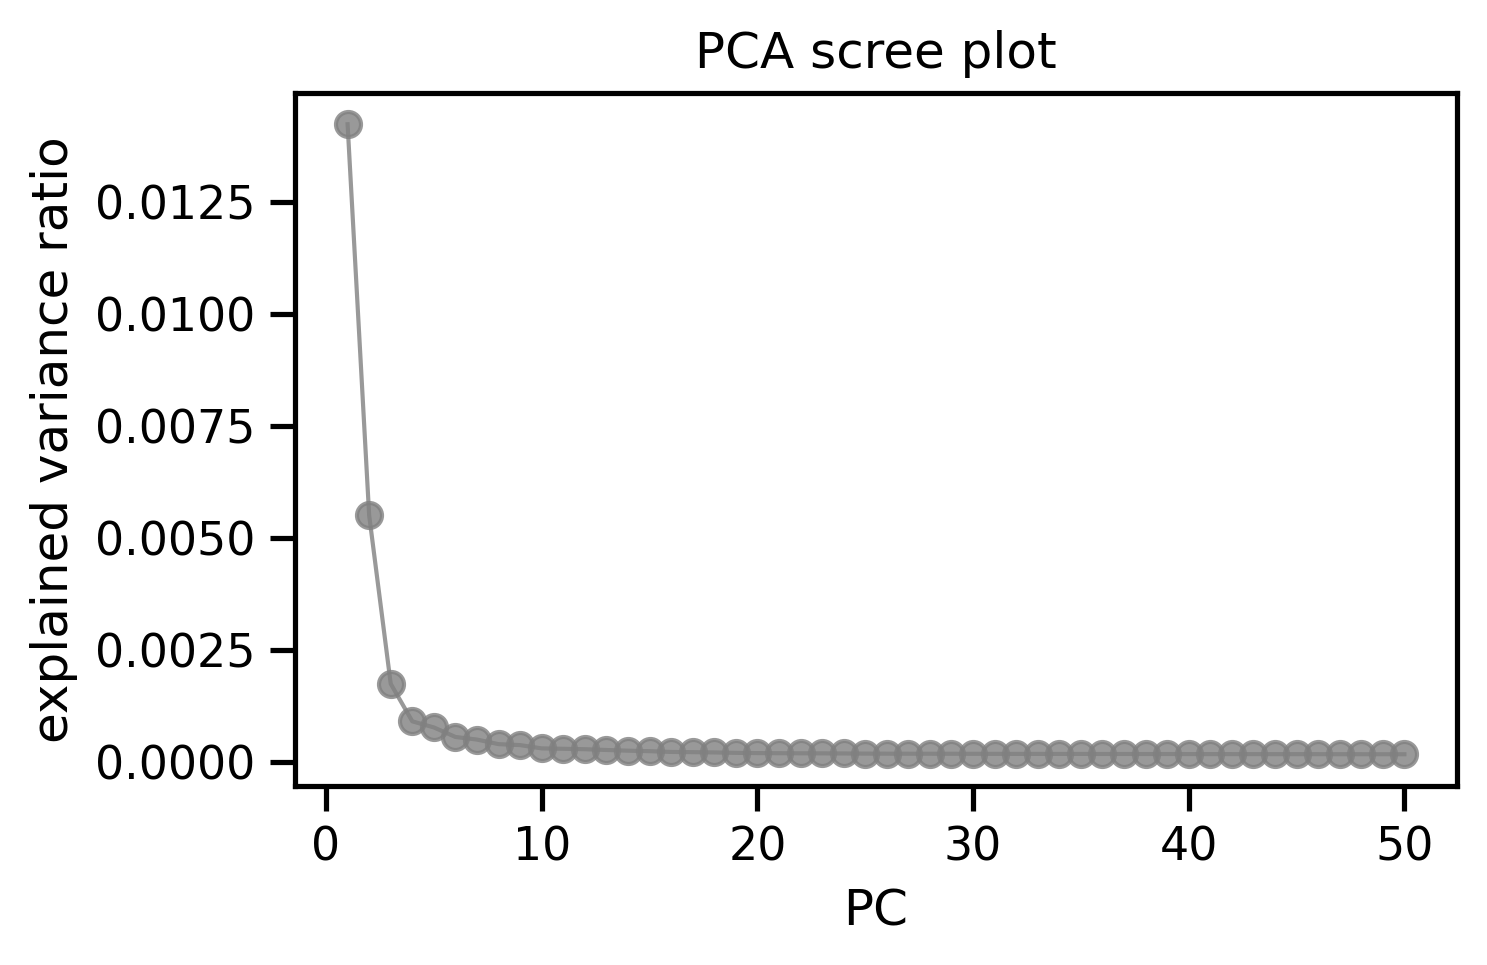

In [6]:
scree_plot(adata)

## Visualize PCA scores

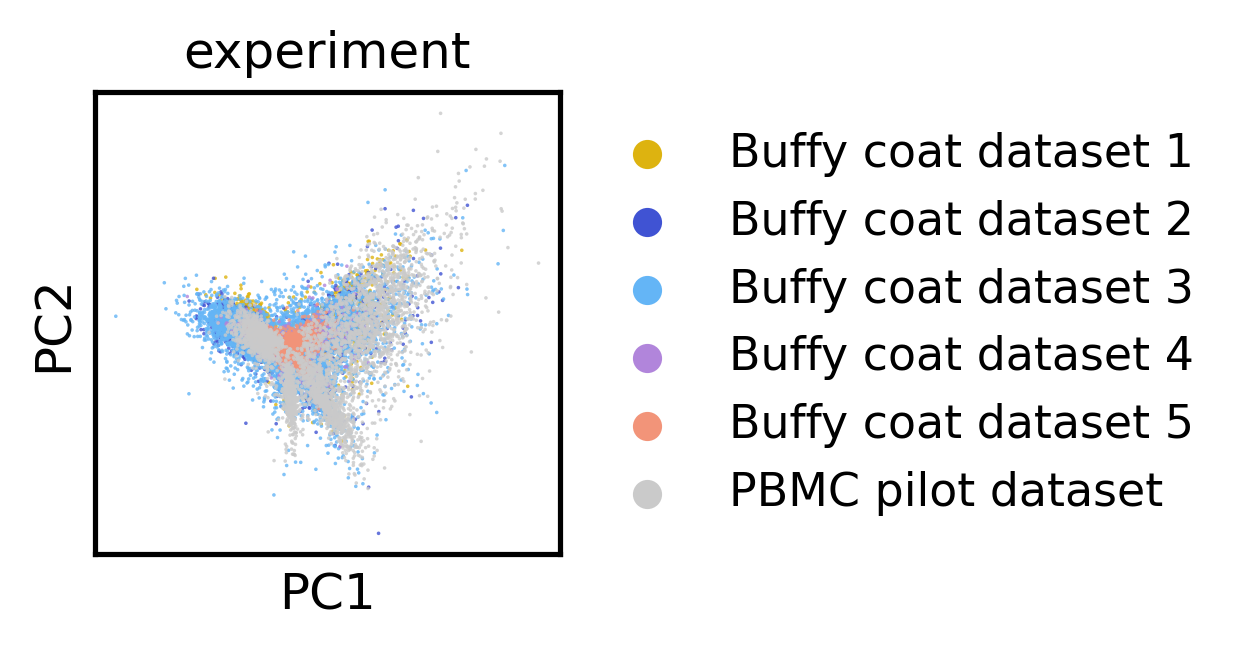

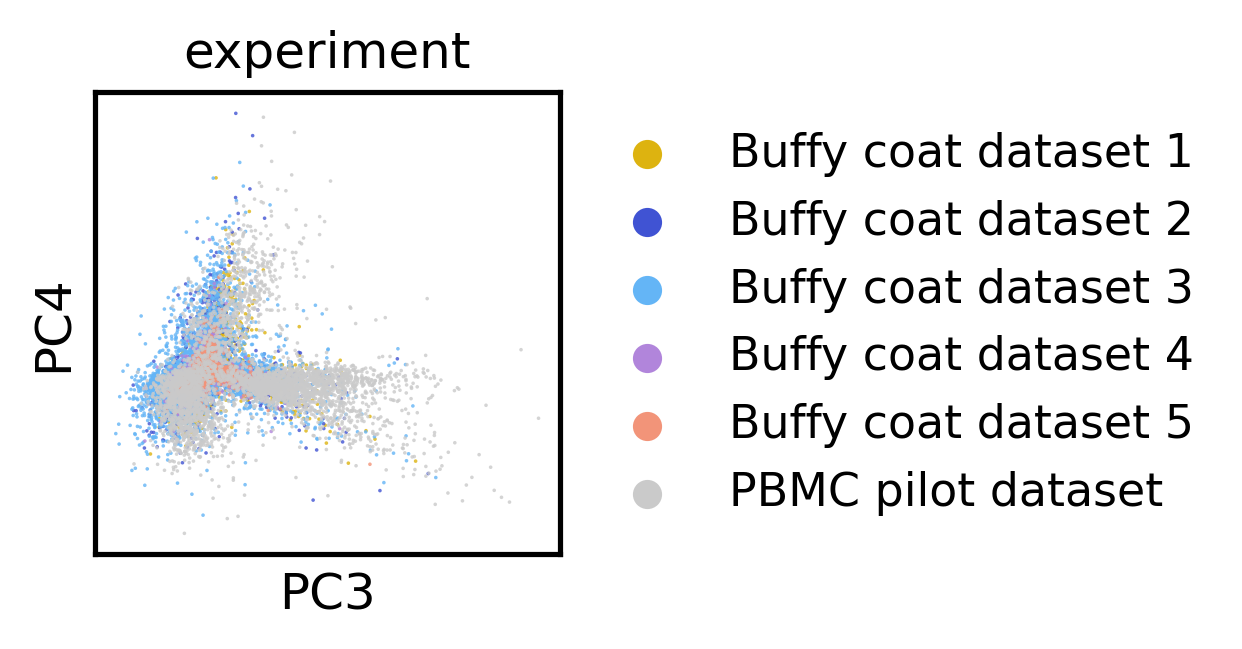

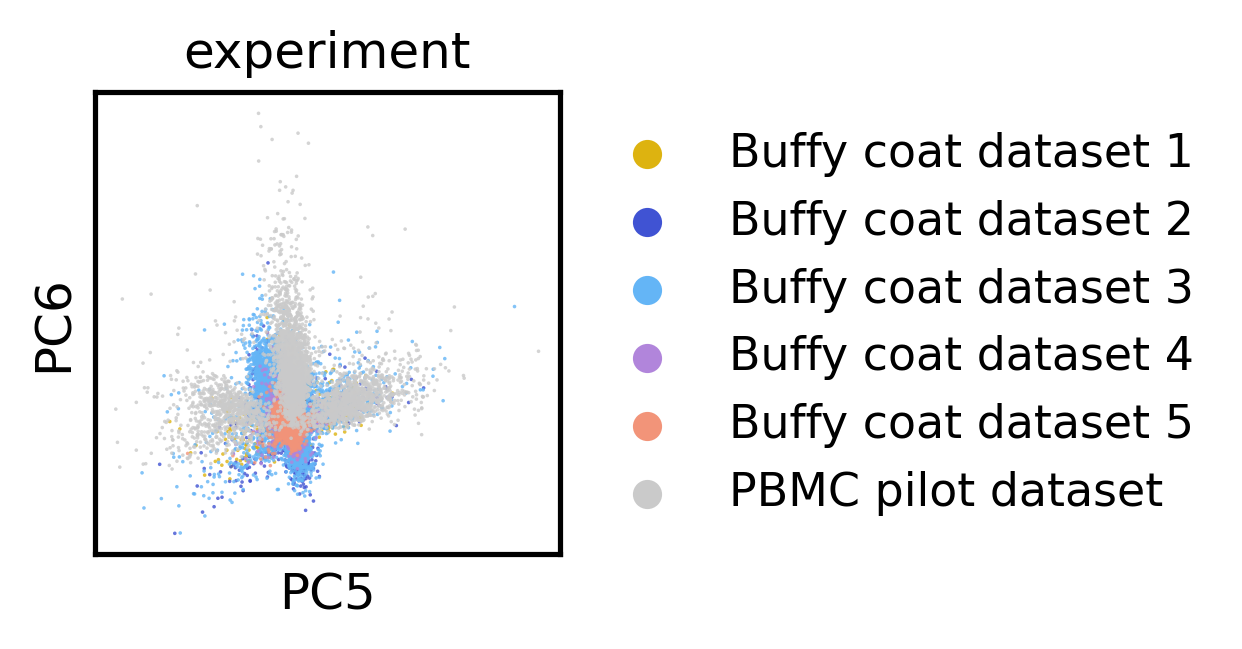

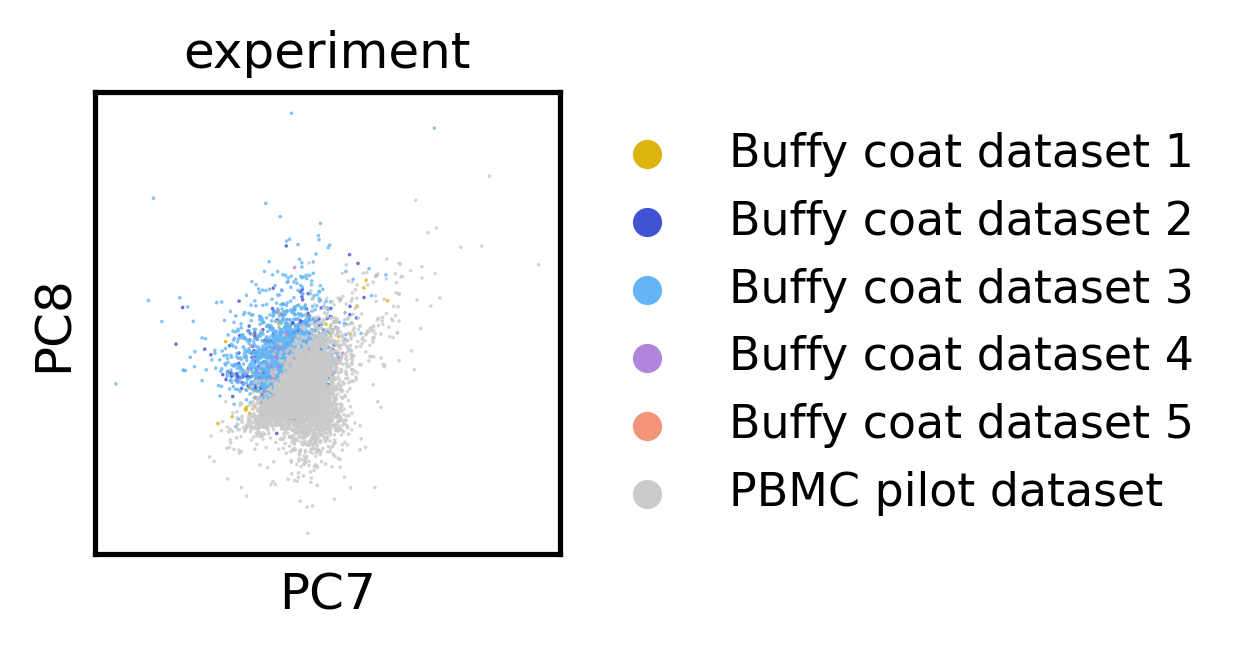

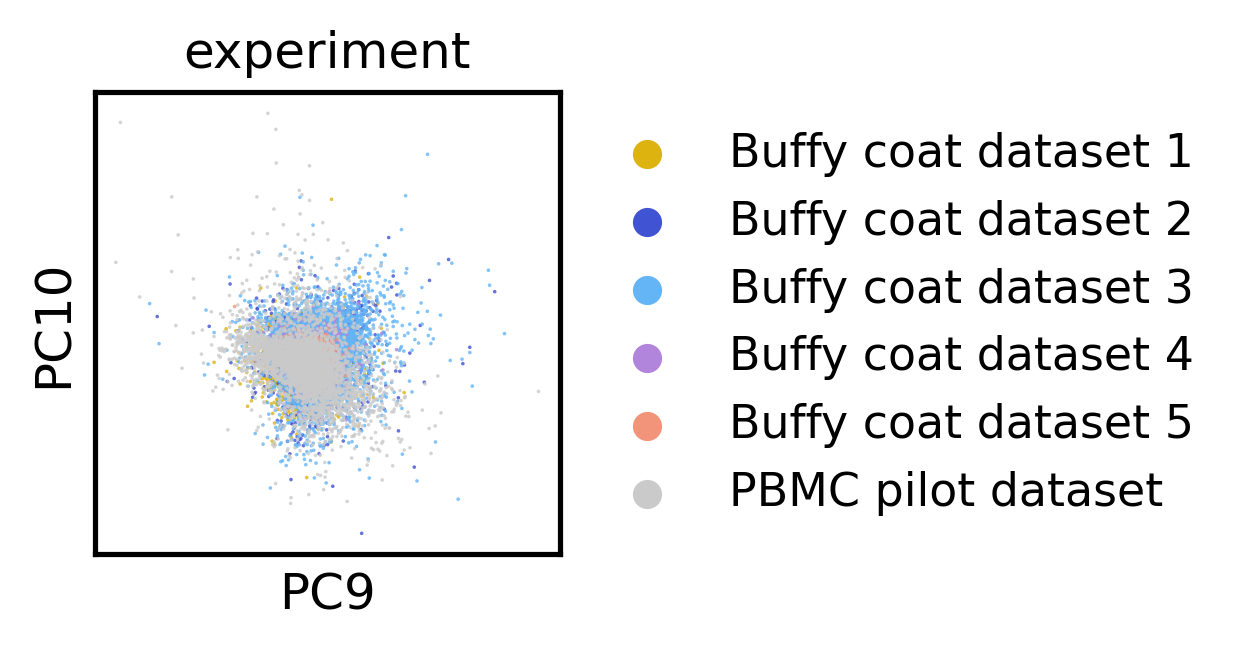

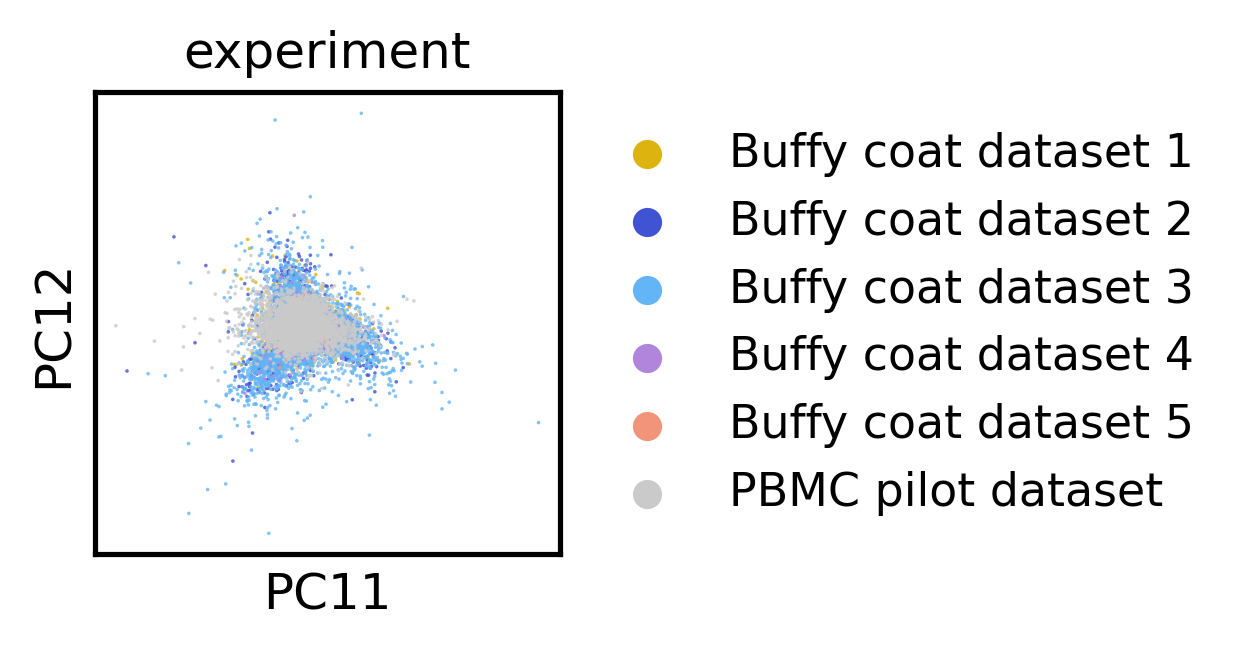

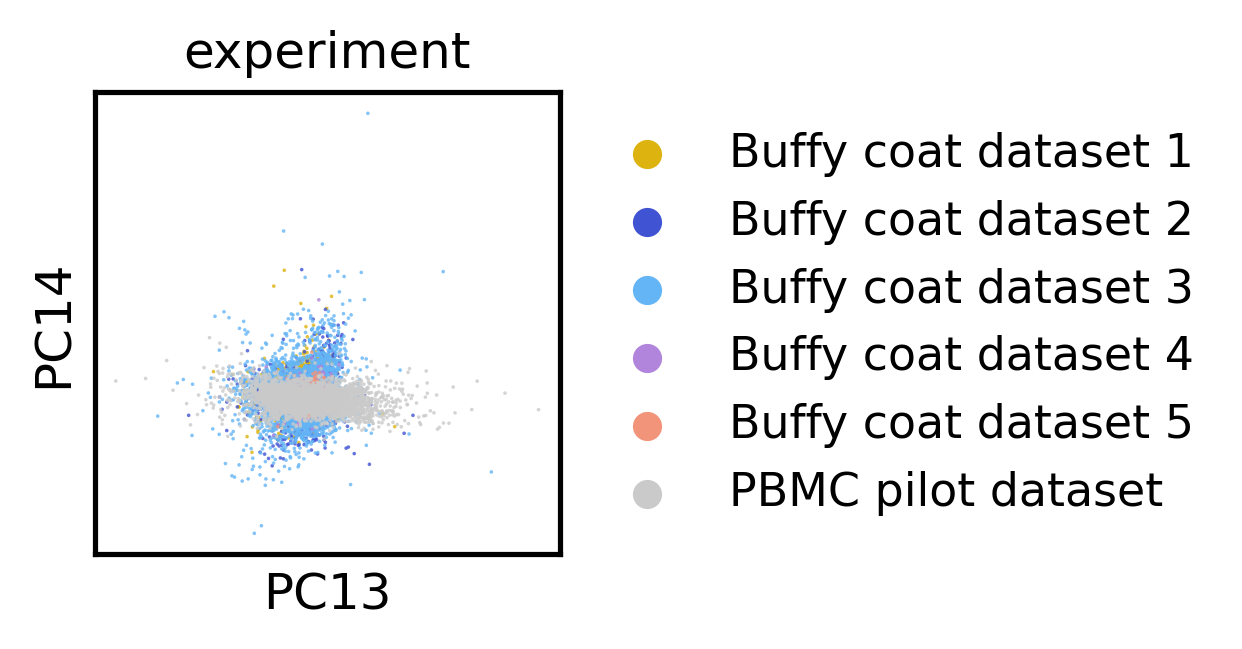

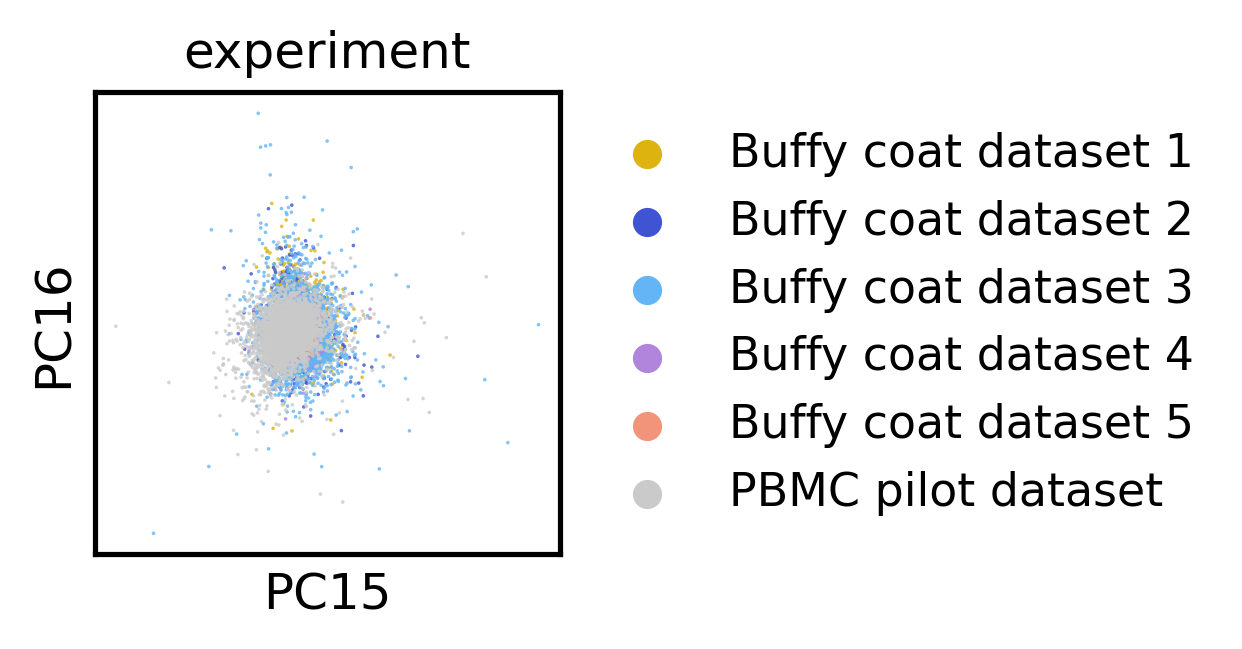

In [7]:
# Visualize PCA scores
plt.rcParams['figure.figsize'] = (2,2)
plot_pcs = [['1,2'], ['3,4'], ['5,6'], ['7,8'], ['9,10'], ['11,12'], ['13,14'], ['15,16']]
for pc_pair in plot_pcs:
    sc.pl.pca(adata, 
              color='experiment', 
              components=pc_pair, alpha=alpha, size=dotsize, 
              palette = experiment_palette
             )

## Compute NN graph based on the top PCs

In [11]:
n_components = 15
n_neighbors = 20

print(f'Using {n_components} PCs to compute NN graph.')
sc.pp.neighbors(adata, n_neighbors=n_neighbors, n_pcs=n_components)

Using 15 PCs to compute NN graph.


/staging/leuven/stg_00064/Xinran/sw/miniconda3/envs/scarches/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Compute UMAP

In [12]:
sc.tl.umap(adata, random_state=42, min_dist=0.15)

## 💾 Save plots

In [9]:
sc.settings.set_figure_params(dpi=120, dpi_save=600, format='png')
plt.rcParams['figure.figsize'] = (3.3,3)
prefix = f'sciMET_BC.{context}'

In [11]:
adata.obs['experiment'] = adata.obs['experiment_x']
adata.obs['donor_id'] = adata.obs['donor_id_x']
adata.obs['NCGN_perc'] = adata.obs['NCGN_perc_x']
adata.obs['NCHN_perc'] = adata.obs['NCHN_perc_x']
adata.obs['coverage'] = adata.obs['coverage_x']
adata.obs['depth'] = adata.obs['depth_x']

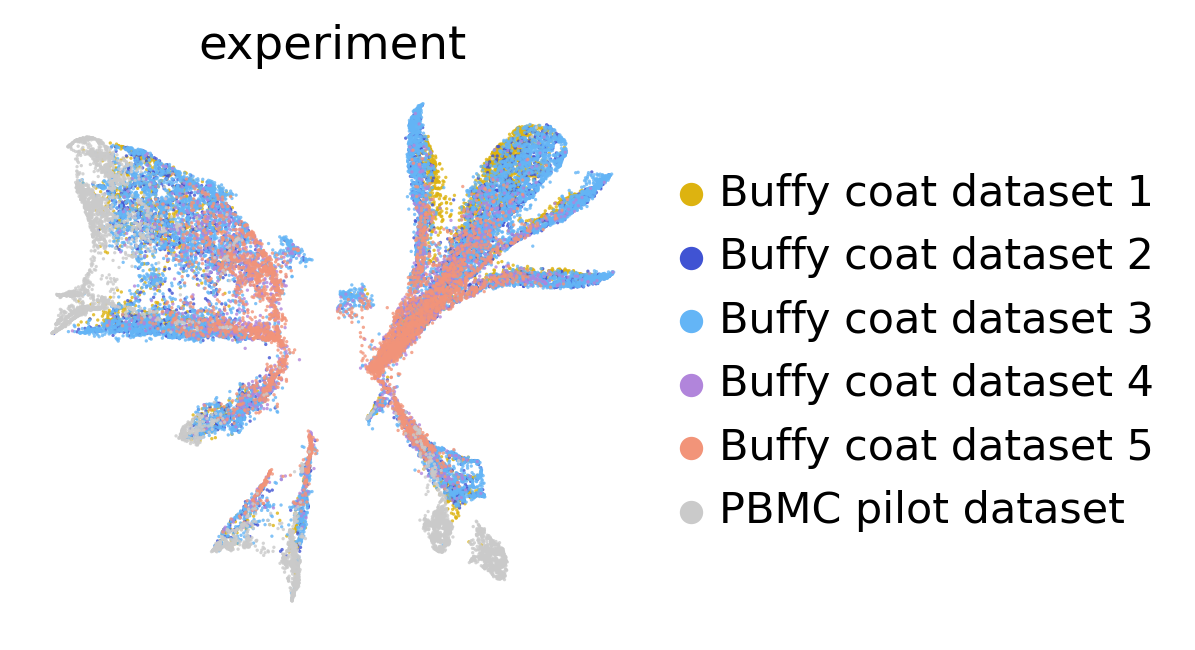

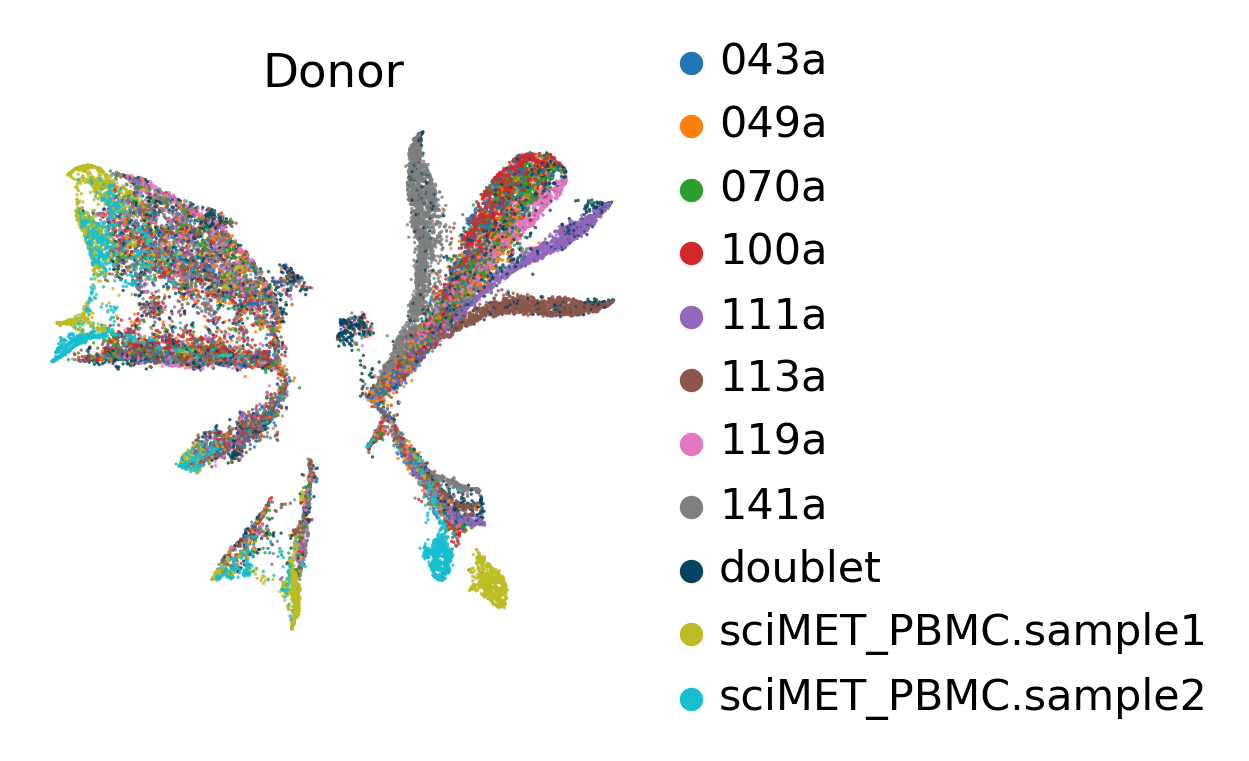

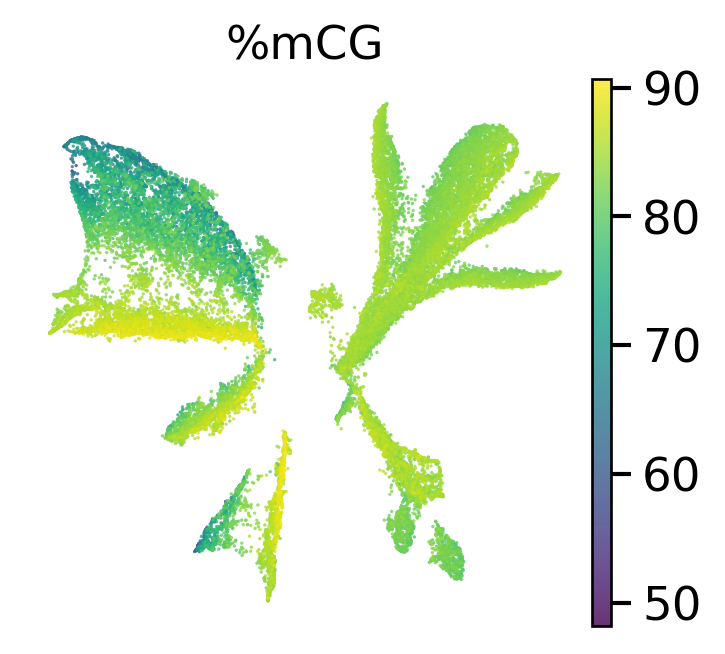

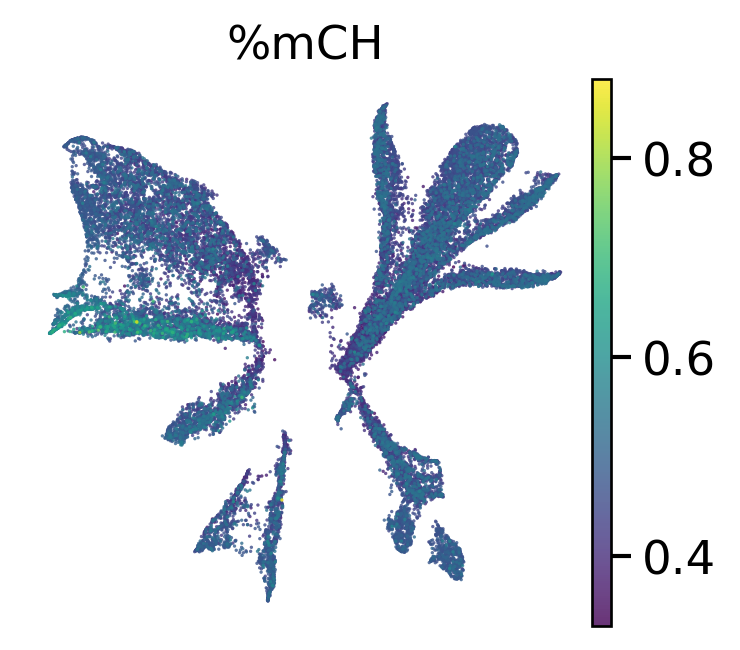

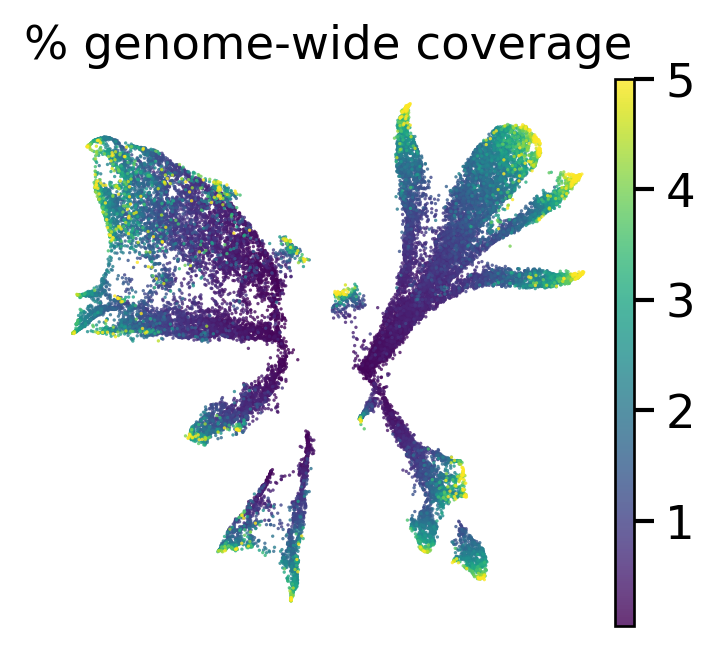

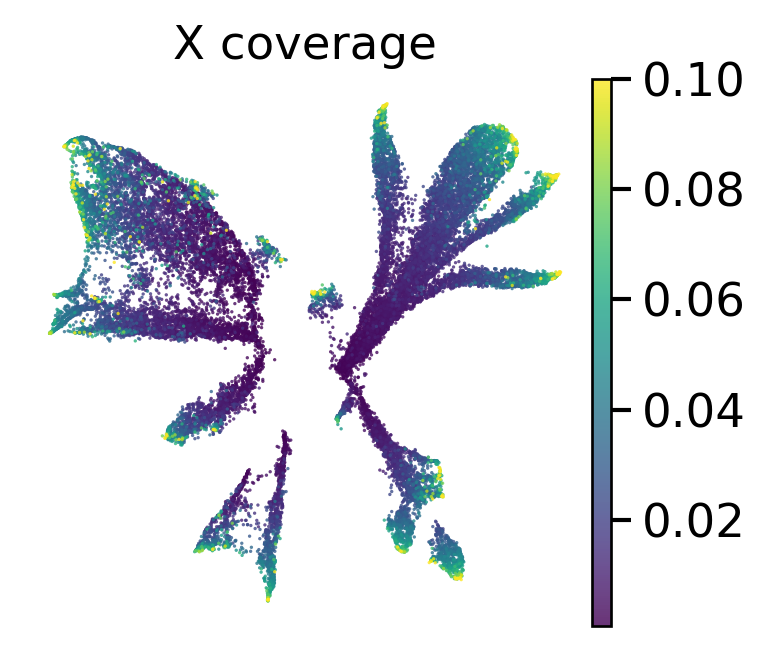

In [13]:
# color by batch
format='png'

sc.pl.umap(adata, color='experiment', alpha=alpha, frameon=False, palette = experiment_palette, 
           save=f'.{prefix}.color_by_experiment.{format}'
          )

sc.pl.umap(adata, color='donor_id', title='Donor', alpha=alpha, frameon=False, palette = donor_palette2,
           save=f'.{prefix}.color_by_donor_id.{format}'
          )

# color by QC metrics
sc.pl.umap(adata, color='NCGN_perc', title='%mCG', alpha=alpha, frameon=False, save=f'.{prefix}.color_by_mCG.{format}')
sc.pl.umap(adata, color='NCHN_perc', title='%mCH', alpha=alpha, frameon=False, save=f'.{prefix}.color_by_mCH.{format}')
sc.pl.umap(adata, color='coverage', title='% genome-wide coverage', alpha=alpha, vmax=5, frameon=False, save=f'.{prefix}.color_by_coverage.{format}')
sc.pl.umap(adata, color='depth', title='X coverage', alpha=alpha, vmax=0.1, frameon=False, save=f'.{prefix}.color_by_depth.{format}')

## Leiden clustering

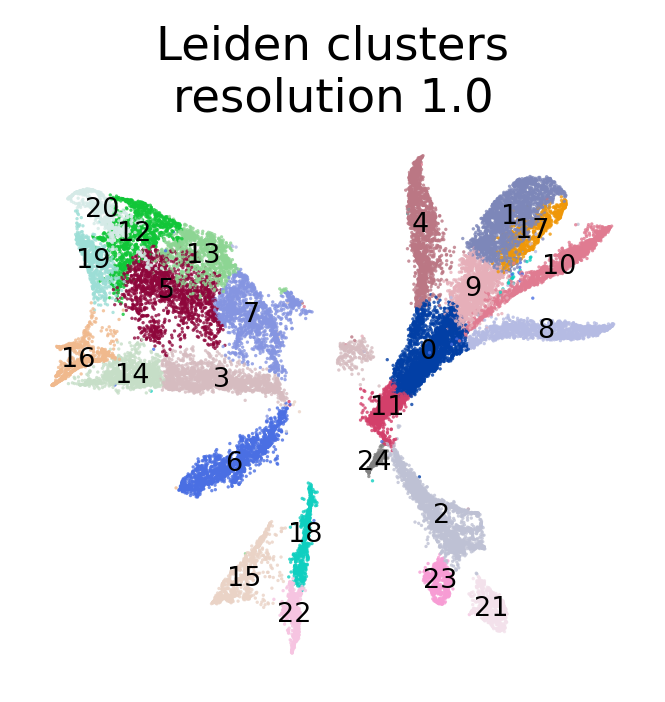

In [56]:
adata.uns.pop('leiden_colors', None)
clustering_res = 1.0
sc.tl.leiden(adata, resolution=clustering_res)

sc.pl.umap(adata, color='leiden', alpha=alpha, title=f"Leiden clusters\nresolution {clustering_res}",
           legend_loc='on data', legend_fontsize='xx-small', legend_fontweight='normal', frameon=False, 
           save=f'.{prefix}.color_by_leiden.res_{clustering_res}.{format}'
          )

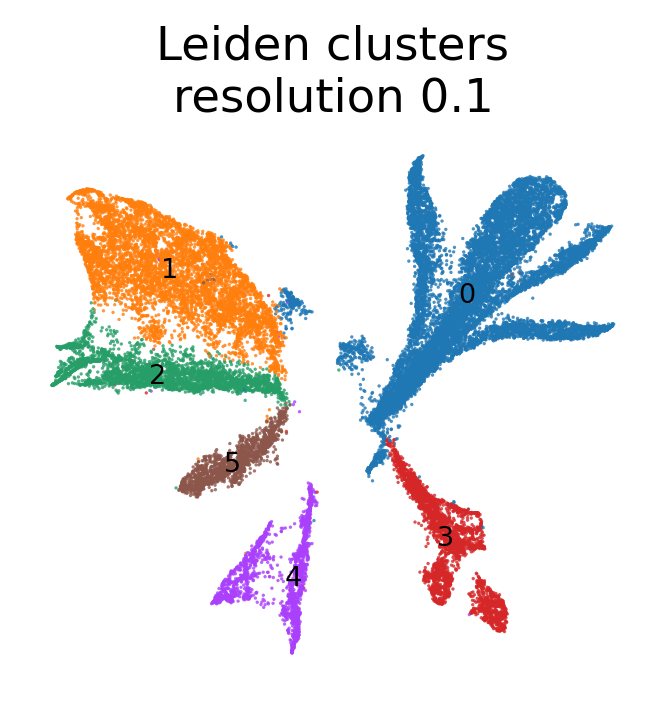

In [57]:
adata.uns.pop('leiden_colors', None)
clustering_res = 0.1
sc.tl.leiden(adata, resolution=clustering_res)

sc.pl.umap(adata, color='leiden', alpha=alpha, title=f"Leiden clusters\nresolution {clustering_res}",
           legend_loc='on data', legend_fontsize='xx-small', legend_fontweight='normal', frameon=False, 
           save=f'.{prefix}.color_by_leiden.res_{clustering_res}.{format}'
          )

# Clustering analysis with doublet detection

In [1]:
import sys
sys.path.append('/data/leuven/357/vsc35706/notebook/sciMET/scripts/analysis')
from doublet_detection import *
sys.path.append('/data/leuven/357/vsc35706/notebook/sciMET/sciMET_PBMC/utils')
from utils import *

os.makedirs('adata', exist_ok=True)
context = 'debias_VMR'

## Load prepared h5ad from methscan output

In [2]:
%%time
adata = sc.read_h5ad('methscan_outs/VMR_matrix/matrices/MSR.h5ad')
adata

CPU times: user 509 ms, sys: 4.09 s, total: 4.6 s
Wall time: 10 s


AnnData object with n_obs × n_vars = 29741 × 72821
    uns: 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: 'MSR'

## Load metadata from QC

In [3]:
def add_obs(adata):
    adata.obs['barcode'] = adata.obs.index.str.split('.var').str[0].str.split('.NCG').str[0]
    # Path to metadata
    meta_path = '/staging/leuven/stg_00064/Xinran/project/sciMET_PBMC/metadata/sciMET_BC.metadata.combined.with_donor_id.input.csv'
    metadata = pd.read_csv(meta_path)
    
    meta = adata.obs.merge(metadata, on='barcode', how='left')
    meta.index = meta['barcode'].copy()
    meta.index.name = 'index'
    adata.obs = meta.copy()
    adata_out = adata.copy()
    print(adata_out)
    return adata_out

In [4]:
add_obs(adata)

/tmp/ipykernel_3542192/3903532877.py:5: DtypeWarning: Columns (58) have mixed types. Specify dtype option on import or set low_memory=False.
  metadata = pd.read_csv(meta_path)


AnnData object with n_obs × n_vars = 29741 × 72821
    obs: 'barcode', 'trimmed_reads', 'mapped_uniq_reads', 'dedup_uniq_reads', 'filtered_uniq_reads', 'batch', 'uniq_map_rate', 'dup_rate', 'filtered_perc', 'chrM_NCGN_count', 'chrM_NCGN_cov', 'chrM_NCGN_mc', 'chrM_NCGN_perc', 'NCGN_count', 'NCGN_cov', 'NCGN_mc', 'NCGN_perc', 'NCHN_count', 'NCHN_cov', 'NCHN_mc', 'NCHN_perc', 'WCGN_count', 'WCGN_cov', 'WCGN_mc', 'WCGN_perc', 'GCHN_count', 'GCHN_cov', 'GCHN_mc', 'GCHN_perc', 'HCHN_count', 'HCHN_cov', 'HCHN_mc', 'HCHN_perc', 'coverage', 'depth', 'mean_frag_size', 'median_frag_size', 'mode_frag_size', 'tss_enrich', 'FRIP', 'TOTAL_CLUSTERS', 'ALIGNED_READS', 'AT_DROPOUT', 'GC_DROPOUT', 'GC_NC_0_19', 'GC_NC_20_39', 'GC_NC_40_59', 'GC_NC_60_79', 'GC_NC_80_100', 'i7', 'i5', 'tgmt', 'i7_well', 'i5_well', 'tgmt_well', 'tgmt_plate', 'donor_id', 'dataset', 'cell_type_PBMC', 'experiment'
    uns: 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: 'MSR'


AnnData object with n_obs × n_vars = 29741 × 72821
    obs: 'barcode', 'trimmed_reads', 'mapped_uniq_reads', 'dedup_uniq_reads', 'filtered_uniq_reads', 'batch', 'uniq_map_rate', 'dup_rate', 'filtered_perc', 'chrM_NCGN_count', 'chrM_NCGN_cov', 'chrM_NCGN_mc', 'chrM_NCGN_perc', 'NCGN_count', 'NCGN_cov', 'NCGN_mc', 'NCGN_perc', 'NCHN_count', 'NCHN_cov', 'NCHN_mc', 'NCHN_perc', 'WCGN_count', 'WCGN_cov', 'WCGN_mc', 'WCGN_perc', 'GCHN_count', 'GCHN_cov', 'GCHN_mc', 'GCHN_perc', 'HCHN_count', 'HCHN_cov', 'HCHN_mc', 'HCHN_perc', 'coverage', 'depth', 'mean_frag_size', 'median_frag_size', 'mode_frag_size', 'tss_enrich', 'FRIP', 'TOTAL_CLUSTERS', 'ALIGNED_READS', 'AT_DROPOUT', 'GC_DROPOUT', 'GC_NC_0_19', 'GC_NC_20_39', 'GC_NC_40_59', 'GC_NC_60_79', 'GC_NC_80_100', 'i7', 'i5', 'tgmt', 'i7_well', 'i5_well', 'tgmt_well', 'tgmt_plate', 'donor_id', 'dataset', 'cell_type_PBMC', 'experiment'
    uns: 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: 'MSR'

## Truncated SVD

In [5]:
#%%time
#sc.tl.pca(adata, zero_center=True)

In [6]:
def scree_plot(adata):
    plt.rcParams['figure.figsize'] = (5,3)
    vr = adata.uns["pca"]["variance_ratio"]
    plt.plot(np.arange(1, len(vr) + 1), vr, marker='o', color='grey', linestyle='-', alpha=0.8, linewidth=1)
    plt.xlabel("PC")
    plt.ylabel("explained variance ratio")
    plt.title("PCA scree plot")
    plt.show()

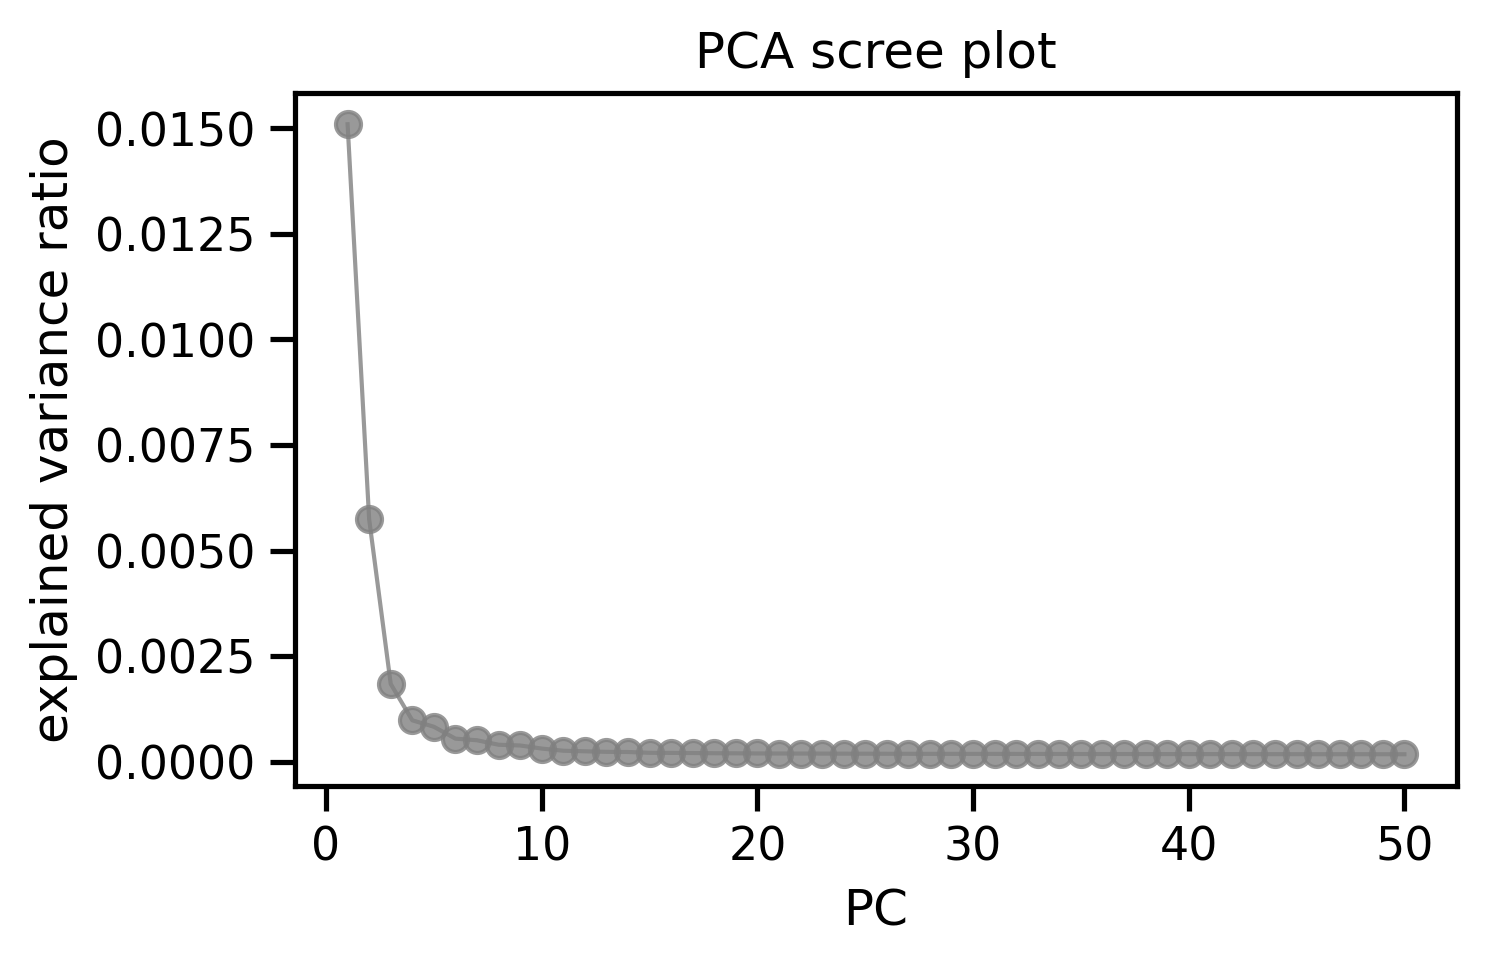

In [7]:
scree_plot(adata)

## Visualize PCA scores

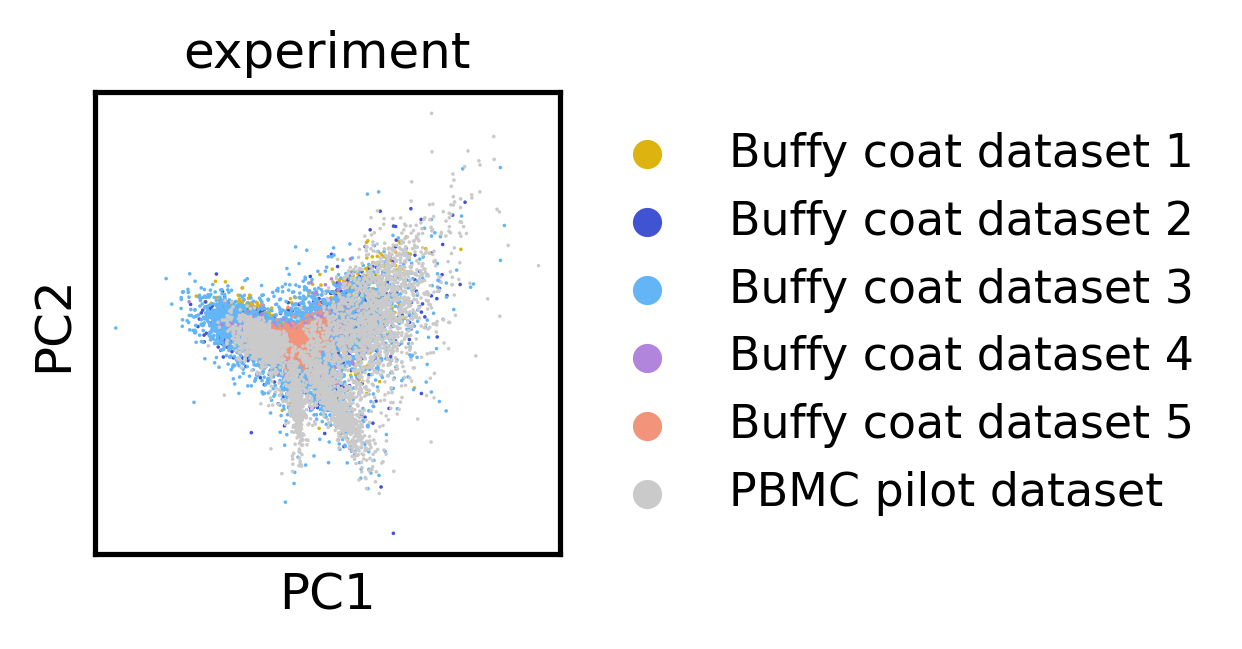

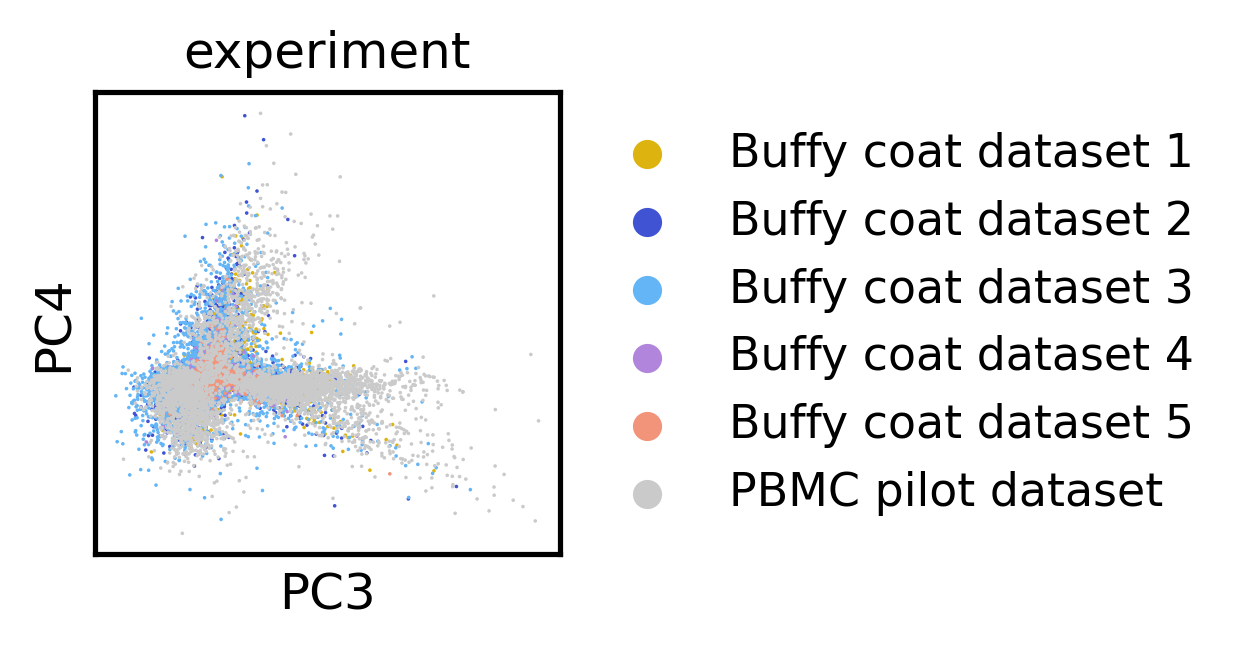

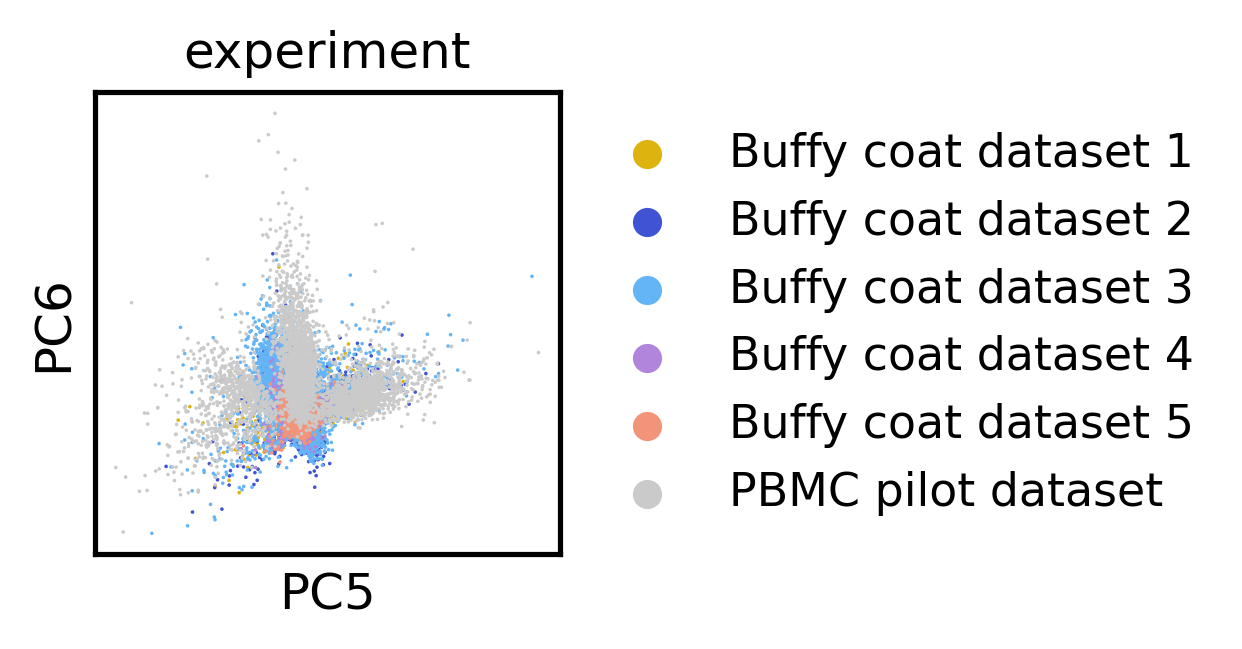

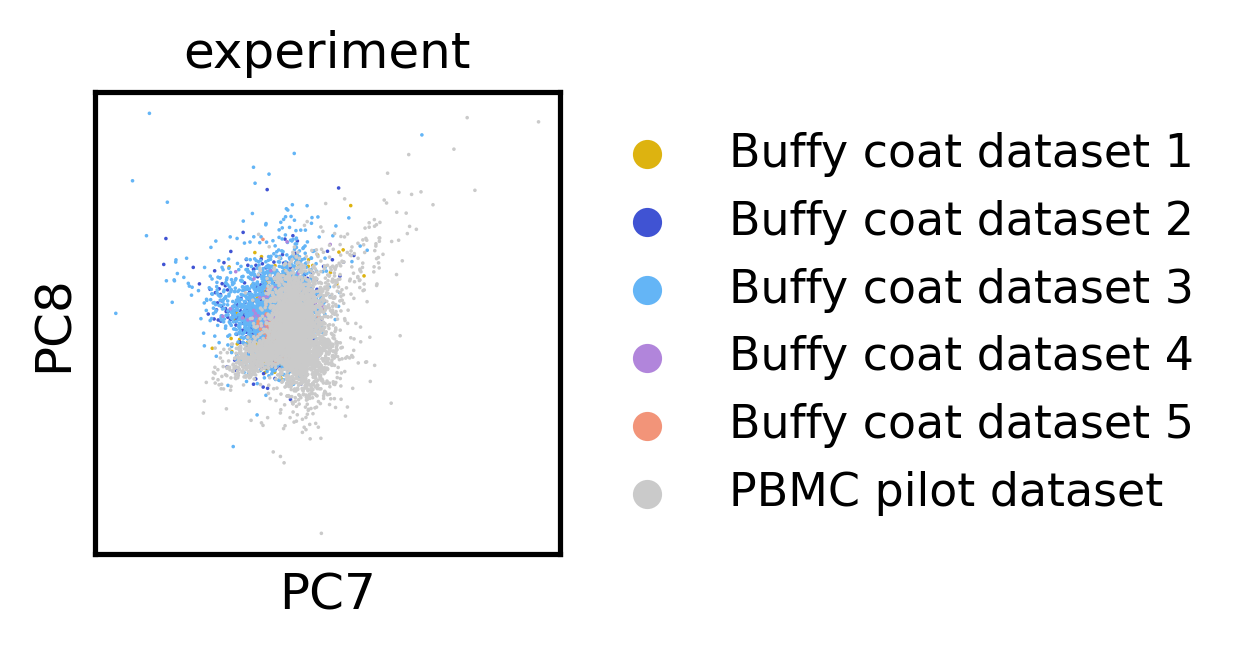

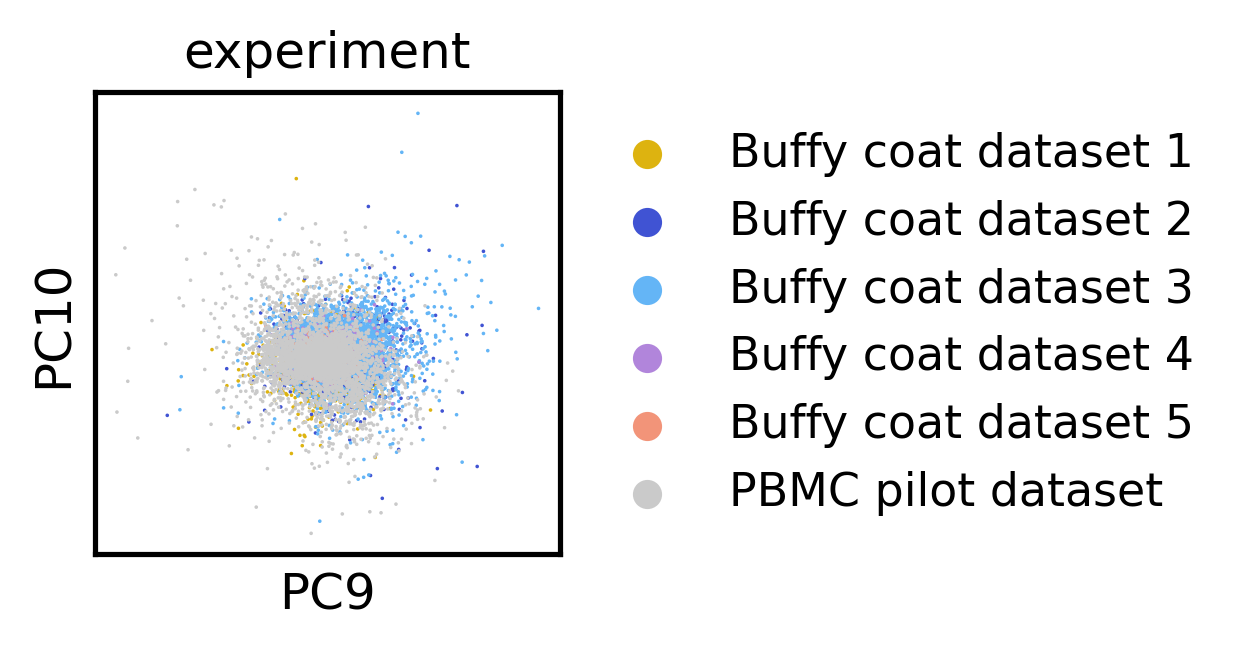

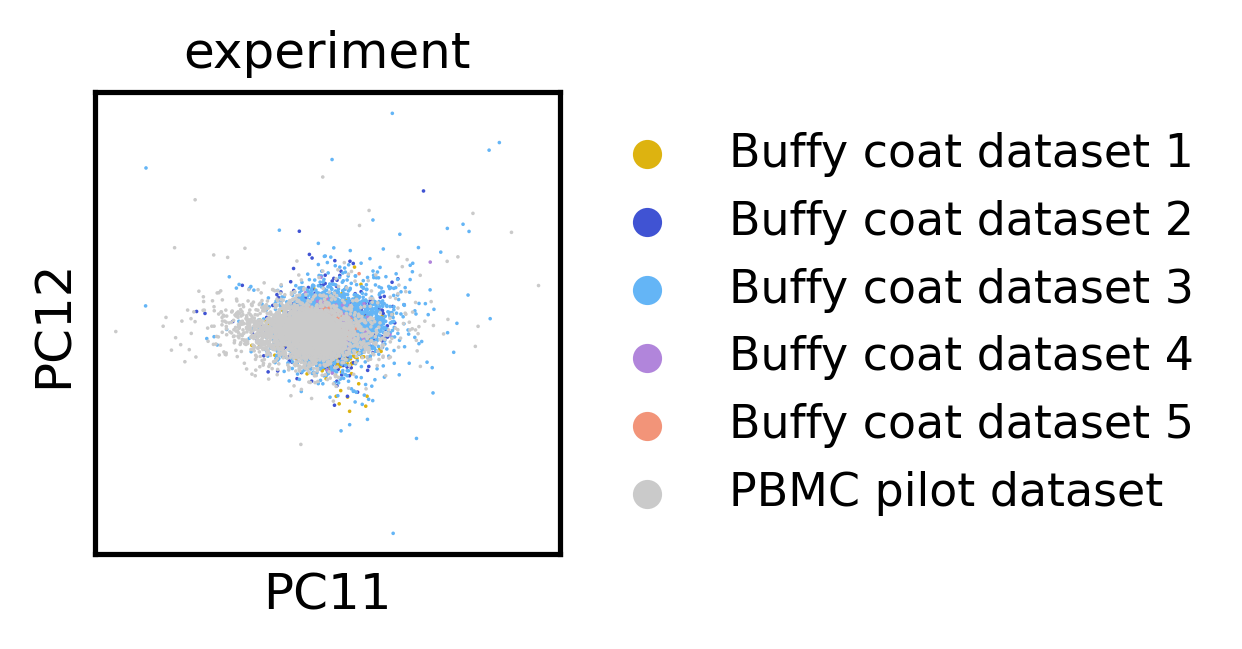

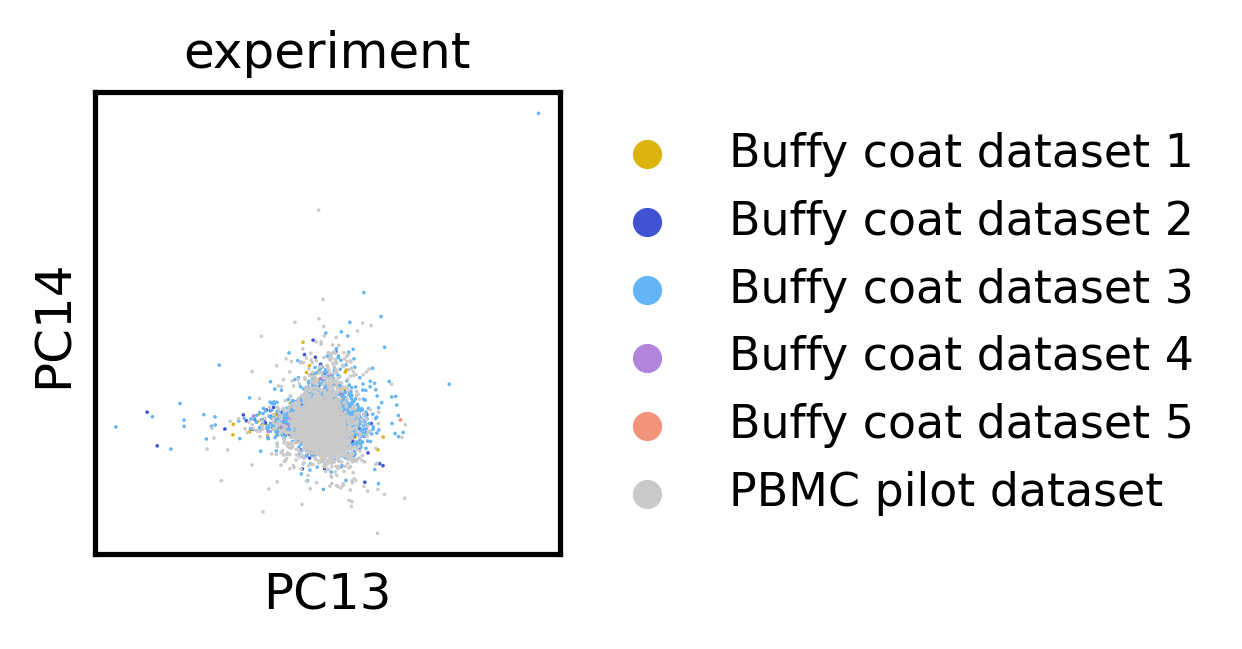

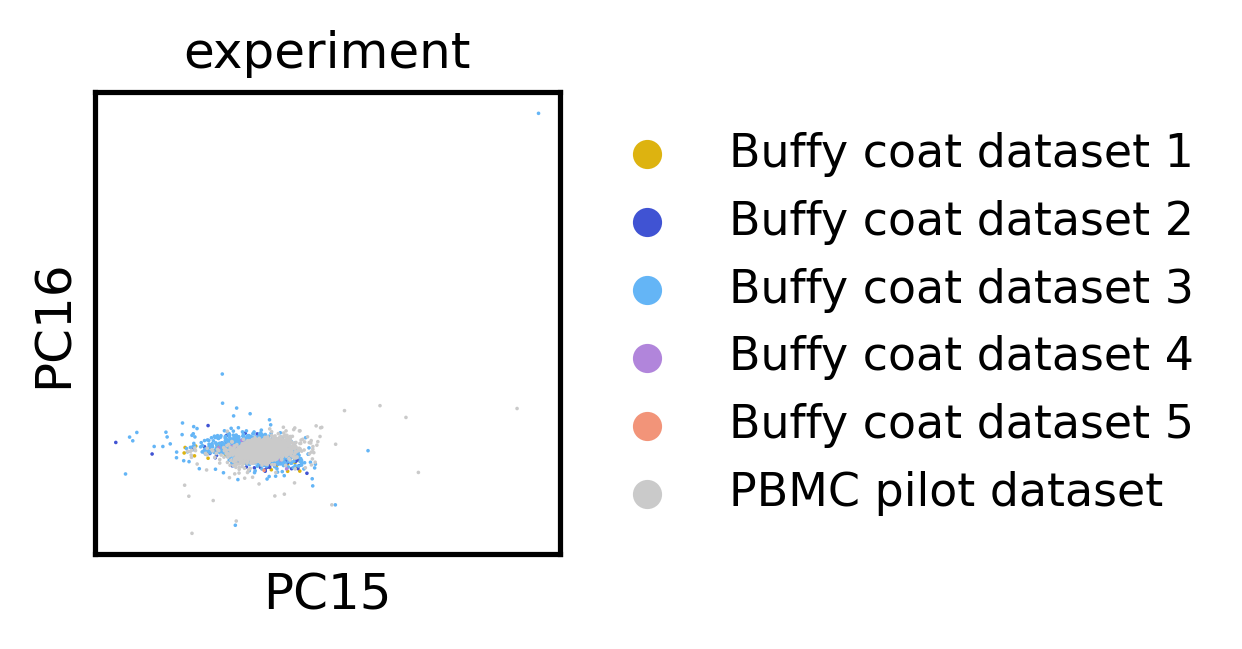

In [8]:
# Visualize PCA scores
plt.rcParams['figure.figsize'] = (2,2)
plot_pcs = [['1,2'], ['3,4'], ['5,6'], ['7,8'], ['9,10'], ['11,12'], ['13,14'], ['15,16']]
for pc_pair in plot_pcs:
    sc.pl.pca(adata, 
              color='experiment', 
              components=pc_pair, alpha=alpha, size=dotsize, 
              palette = experiment_palette
             )

## Compute NN graph based on the top PCs

In [10]:
n_components = 15
n_neighbors = 20 

print(f'Using {n_components} PCs to compute NN graph.')
sc.pp.neighbors(adata, n_neighbors=n_neighbors, n_pcs=n_components)

Using 15 PCs to compute NN graph.


/staging/leuven/stg_00064/Xinran/sw/miniconda3/envs/scarches/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Compute UMAP and t-SNE embedding

In [11]:
sc.tl.umap(adata, random_state=42, min_dist=0.15)

## 💾 Save plots

In [13]:
sc.settings.set_figure_params(dpi=120, dpi_save=600, format='png')
plt.rcParams['figure.figsize'] = (3.3,3)
prefix = f'sciMET_BC.{context}.after_debias'
adata.obs.index=adata.obs['barcode']

In [ ]:
sc.pl.umap(adata, color='experiment', alpha=alpha, frameon=False, palette = experiment_palette, save=f'.{prefix}.color_by_experiment.pdf')
sc.pl.umap(adata, color='NCGN_perc', title='%mCG', alpha=alpha, frameon=False, save=f'.{prefix}.color_by_mCG.pdf')
sc.pl.umap(adata, color='NCHN_perc', title='%mCH', alpha=alpha, frameon=False, save=f'.{prefix}.color_by_mCH.pdf')
sc.pl.umap(adata, color='coverage', title='% genome-wide coverage', alpha=alpha, vmax=5, frameon=False, save=f'.{prefix}.color_by_coverage.pdf')
sc.pl.umap(adata, color='depth', title='X coverage', alpha=alpha, vmax=0.1, frameon=False, save=f'.{prefix}.color_by_depth.pdf')

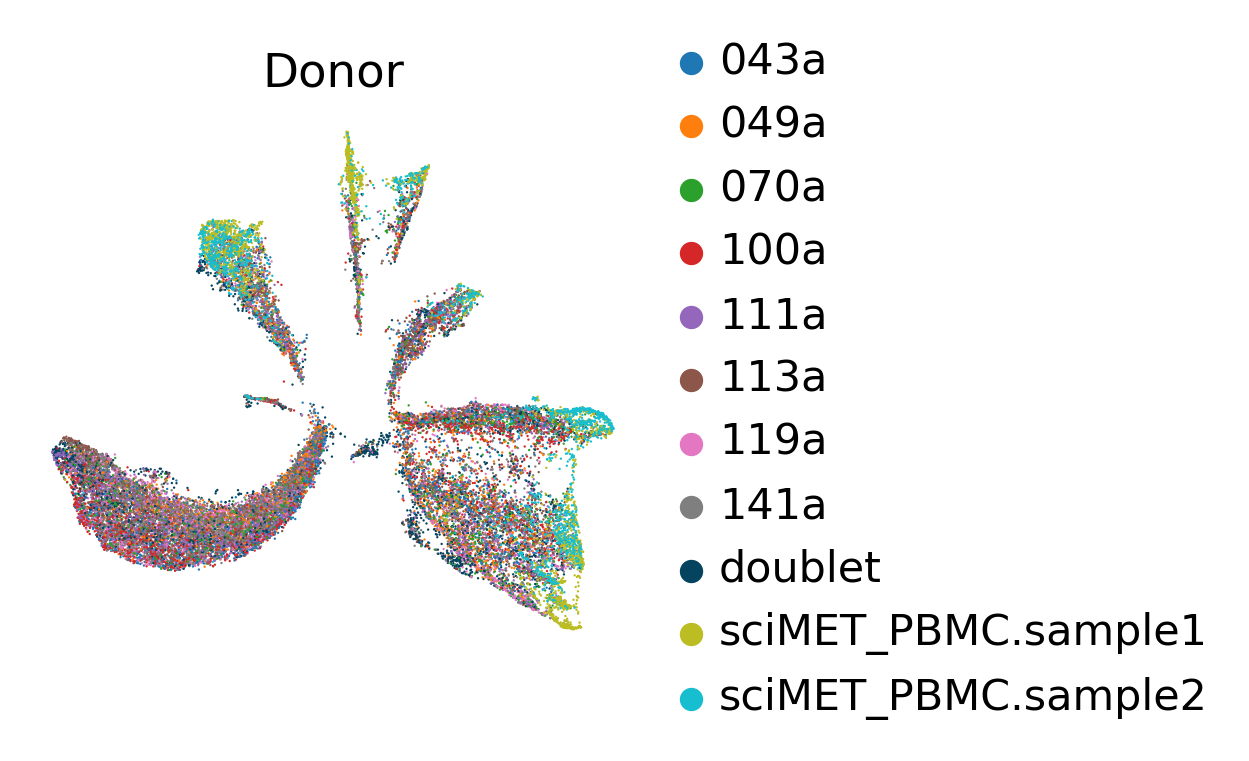

In [18]:
sc.pl.umap(adata, color='donor_id', title='Donor', alpha=alpha, size = 2, frameon=False, palette = donor_palette2, save=f'.{prefix}.color_by_donor_id.png')

## Plot each donor separately

In [120]:
donors = adata.obs['donor_id'].astype('category').cat.categories

for donor in donors:
    safe = str(donor).replace('/', '_').replace(' ', '_')
    sc.pl.umap(
        adata,
        color='donor_id',
        groups=[donor],
        title=f'Donor {donor}',
        alpha=alpha,
        size=4,
        frameon=False,
        palette=donor_palette2,
        na_color='lightgrey',
        save=f'.{prefix}.donor_{safe}.png',
        show=False,
    )

## Leiden clustering

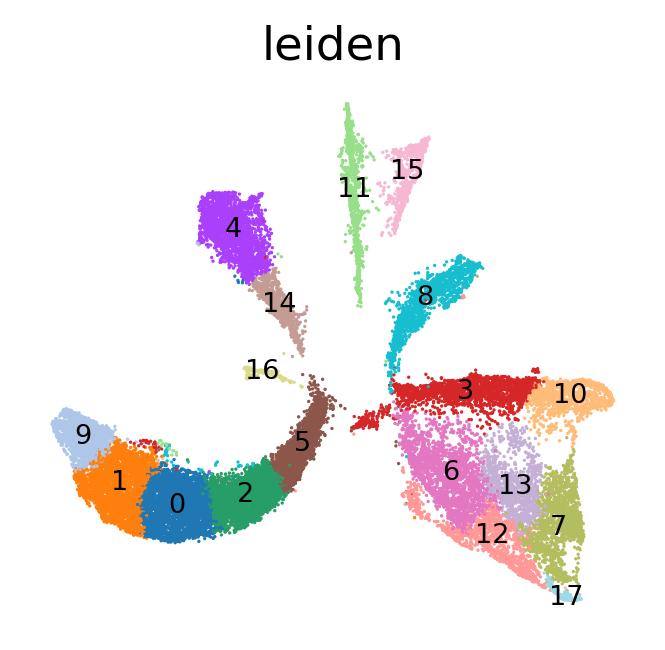

In [20]:
adata.uns.pop('leiden_colors', None)

clustering_res = 0.8
sc.tl.leiden(adata, resolution=clustering_res)

sc.pl.umap(adata, color='leiden', alpha=alpha, 
           legend_loc='on data', legend_fontsize='xx-small', legend_fontweight='normal', frameon=False, 
           save=f'.{prefix}.color_by_leiden.res_{clustering_res}.pdf'
          )

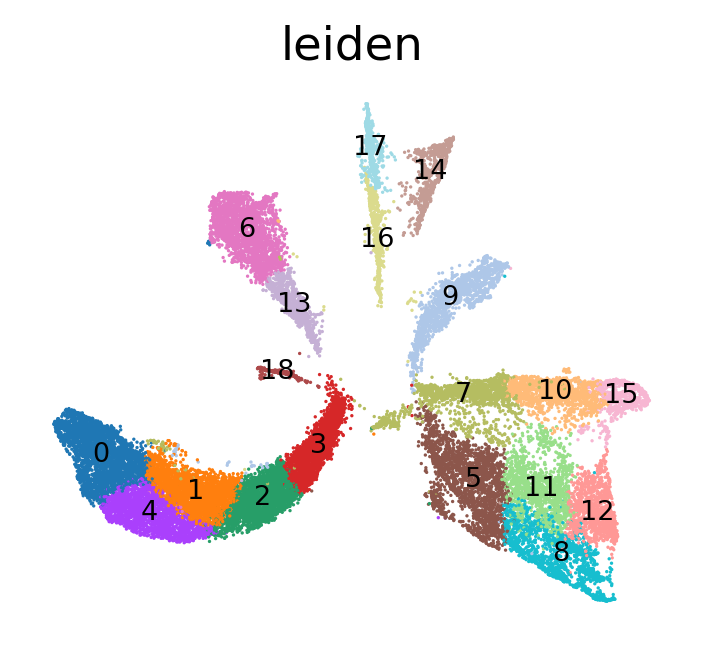

In [43]:
adata.uns.pop('leiden_colors', None)

clustering_res = 1.0
sc.tl.leiden(adata, resolution=clustering_res)

sc.pl.umap(adata, color='leiden', alpha=alpha, 
           legend_loc='on data', legend_fontsize='xx-small', legend_fontweight='normal', frameon=False, 
           save=f'.{prefix}.color_by_leiden.res_{clustering_res}.pdf'
          )

## Identify doublet cluster

In [97]:
df = adata.obs

perc_doublet = (
    df
    .groupby('leiden')
    .apply(lambda x: (x['donor_id'] == 'doublet').mean() * 100)
    .reset_index(name='percent_doublet')
)
perc_doublet['doublet_cluster'] = perc_doublet['percent_doublet']>50
perc_doublet

,leiden,percent_doublet,doublet_cluster
0,0,5.126582,False
1,1,5.796089,False
2,2,3.879941,False
3,3,5.058875,False
4,4,8.172589,False
5,5,5.552618,False
6,6,9.774436,False
7,7,17.523810,False
8,8,5.738233,False
9,9,10.130048,False


In [98]:
doublet_cluster = perc_doublet.loc[perc_doublet['doublet_cluster']]['leiden'].tolist()
print(doublet_cluster)

['19']


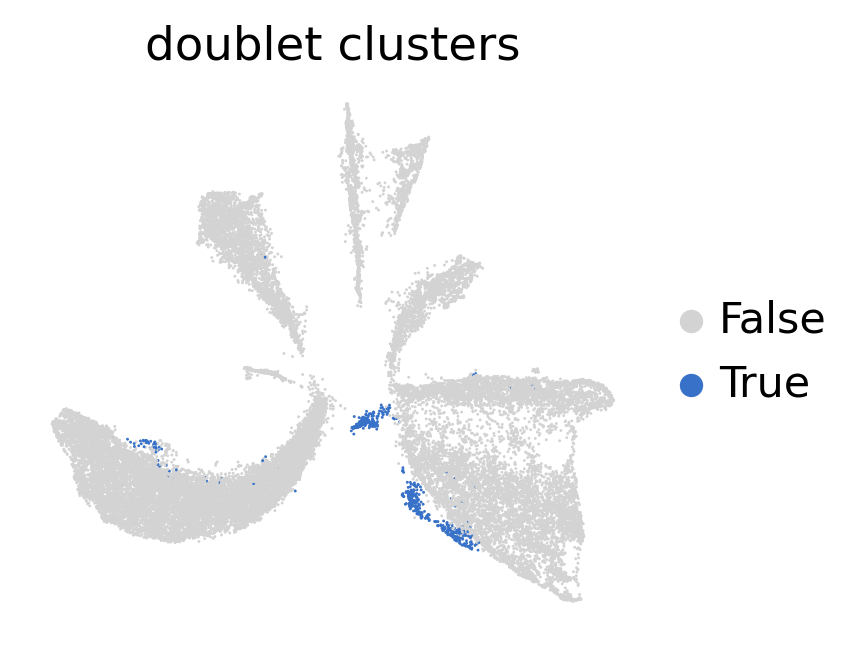

In [99]:
adata.obs['doublet_cluster'] = adata.obs['leiden'].isin(doublet_cluster).astype(str)
sc.pl.umap(adata, color='doublet_cluster', alpha=1, size=3, frameon=False, 
           title="doublet clusters", palette=doublet_palette, show=True, save=f'.{prefix}.color_by_doublet_clusters.pdf')

In [115]:
adata.obs.loc[adata.obs['doublet_cluster']=='True'].shape[0]

590

## Plot probability for doublet from **vireo output**

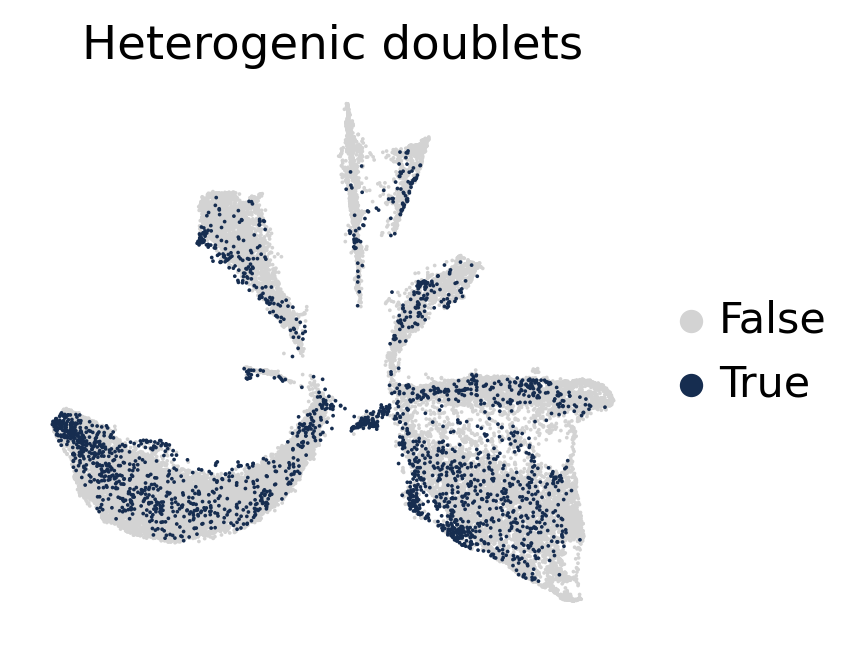

In [35]:
doublet_palette = {
    'True':'#162D50', 
    'False':'lightgray'
}

# Create a binary column for doublets
adata.obs['is_heterogenic_doublet'] = (adata.obs['donor_id'] == 'doublet').astype(str)

# Sort the AnnData object so doublets are plotted last
# Create a sort key: doublets get value 1, others get 0
sort_key = (adata.obs['donor_id'] == 'doublet').astype(int)
adata = adata[sort_key.argsort()]  # This sorts False first, True last

# Plot with the binary column
sc.pl.umap(adata, color='is_heterogenic_doublet', alpha=1, size=5, frameon=False, 
           title="Heterogenic doublets", palette=doublet_palette, show=True, save=f'.{prefix}.color_by_heterogenic_doublet.pdf')

In [36]:
adata.obs['is_heterogenic_doublet'].value_counts()

False    27322
True      2419
Name: is_heterogenic_doublet, dtype: int64

In [37]:
obs = adata.obs.copy()
obs.index.name = 'index'
file = "/staging/leuven/stg_00064/Xinran/project/sciMET_PBMC/metadata/sciMET_BC.metadata.combined.with_donor_id.without_cell_type.csv"
add_meta = pd.read_csv(file)[['barcode','prob_doublet','doublet_logLikRatio']]
obs_updated = obs.merge(add_meta, how='left')
obs_updated.index = obs['barcode']
obs_updated.index.name = 'index'
adata.obs = obs_updated.copy()

/tmp/ipykernel_3542192/169520939.py:4: DtypeWarning: Columns (60,61) have mixed types. Specify dtype option on import or set low_memory=False.
  add_meta = pd.read_csv(file)[['barcode','prob_doublet','doublet_logLikRatio']]


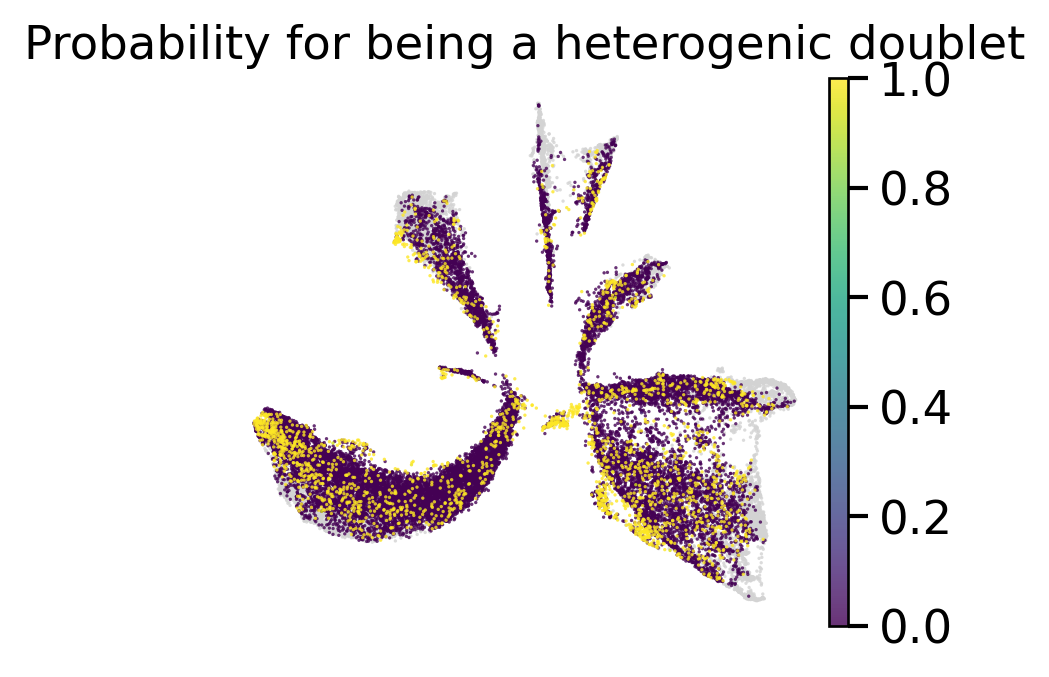

In [38]:
plt.rcParams['figure.figsize'] = (3.5,3)
sc.pl.umap(adata, color='prob_doublet', alpha=0.8, 
           frameon=False, 
           title="Probability for being a heterogenic doublet", 
           save=f'.{prefix}.color_by_heterogenic_prob_doublet.pdf')

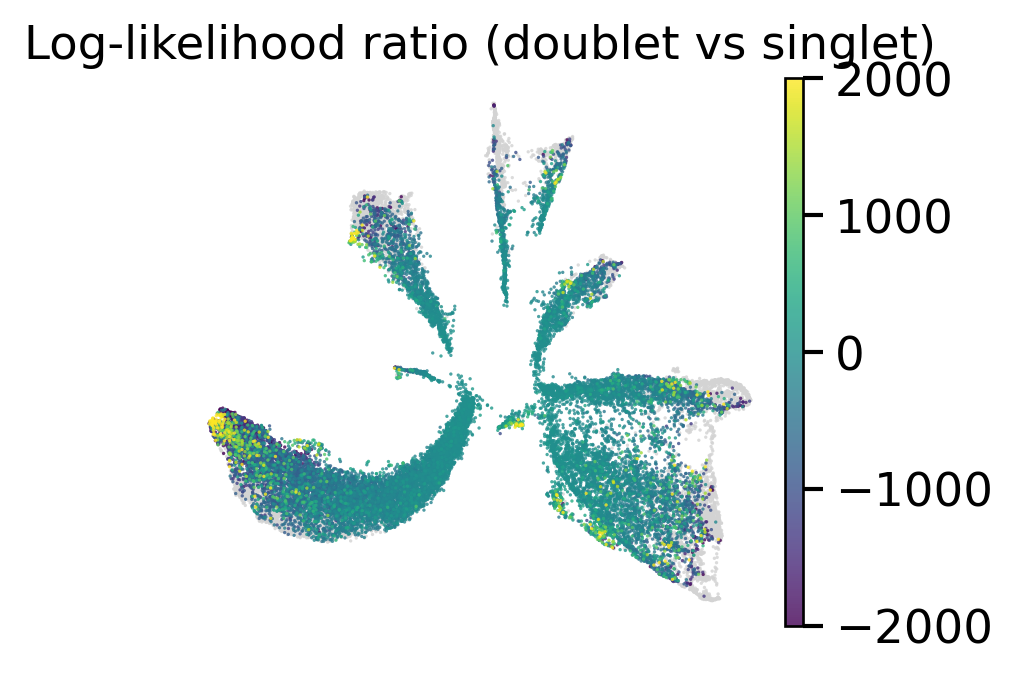

In [39]:
plt.rcParams['figure.figsize'] = (3.5,3)
sc.pl.umap(adata, color='doublet_logLikRatio', alpha=0.8, 
           frameon=False, 
           title = "Log-likelihood ratio (doublet vs singlet)",
           vmin=-2000, vmax=2000,
           save=f'.{prefix}.color_by_doublet_logLikRatio.pdf')

In [40]:
np.log10(adata.obs.doublet_logLikRatio)

/staging/leuven/stg_00064/Xinran/sw/miniconda3/envs/scarches/lib/python3.9/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


index
BC-GC173746.1E07.GGCTATTC_ATCCAAGT_TGACGAAT         NaN
BC-GC173746.1E08.GGCTATTC_ACGGTTAG_CAGTAGGC         NaN
BC-GC173746.1E08.GGCTATTC_AATGGAGG_CAGTAGGC         NaN
BC-GC173746.1E08.GGCTATTC_AATGATGC_CAGTAGGC         NaN
BC-GC173746.1E08.GGCTATTC_AAGTTGAC_CAGTAGGC         NaN
                                                 ...   
BC-GC173745.1E03.TACCGAAG_GTTCTCTC_CAAGCTAG    2.445593
BC-GC173745.1E03.TCGTAGCA_CTATGGCC_CAAGCTAG    3.020197
BC-GC173745.3E12.TAAGTGCG_GGCAGCAG_CAGCGAAT    2.707719
BC-GC173745.1E03.TCGTAGCA_GTTCTCTC_CAAGCTAG    3.065174
BC-GC173745.1E03.TTCTCAGT_GCATTAGG_CAAGCTAG    2.745776
Name: doublet_logLikRatio, Length: 29741, dtype: float64

## Load result of doublet detection

In [45]:
adata_file = 'adata/adata.processed.VMR.artificial_doublets.1.h5ad'
doublet_adata = sc.read_h5ad(adata_file)
doublet_adata

AnnData object with n_obs × n_vars = 27322 × 72821
    obs: 'doublet_status'
    layers: 'MSR'

In [48]:
adata_combined = anndata.concat([adata, doublet_adata], join='outer')
adata_combined

AnnData object with n_obs × n_vars = 57063 × 72821
    obs: 'barcode', 'trimmed_reads', 'mapped_uniq_reads', 'dedup_uniq_reads', 'filtered_uniq_reads', 'batch', 'uniq_map_rate', 'dup_rate', 'filtered_perc', 'chrM_NCGN_count', 'chrM_NCGN_cov', 'chrM_NCGN_mc', 'chrM_NCGN_perc', 'NCGN_count', 'NCGN_cov', 'NCGN_mc', 'NCGN_perc', 'NCHN_count', 'NCHN_cov', 'NCHN_mc', 'NCHN_perc', 'WCGN_count', 'WCGN_cov', 'WCGN_mc', 'WCGN_perc', 'GCHN_count', 'GCHN_cov', 'GCHN_mc', 'GCHN_perc', 'HCHN_count', 'HCHN_cov', 'HCHN_mc', 'HCHN_perc', 'coverage', 'depth', 'mean_frag_size', 'median_frag_size', 'mode_frag_size', 'tss_enrich', 'FRIP', 'TOTAL_CLUSTERS', 'ALIGNED_READS', 'AT_DROPOUT', 'GC_DROPOUT', 'GC_NC_0_19', 'GC_NC_20_39', 'GC_NC_40_59', 'GC_NC_60_79', 'GC_NC_80_100', 'i7', 'i5', 'tgmt', 'i7_well', 'i5_well', 'tgmt_well', 'tgmt_plate', 'donor_id', 'dataset', 'cell_type_PBMC', 'experiment', 'leiden', 'doublet_cluster', 'doublet_status'
    obsm: 'X_pca', 'X_umap'
    layers: 'MSR'

In [49]:
# n_obs = number of real cells, n_sim = number of doublets
n_obs = adata.n_obs  # original cells
n_sim = adata_combined.n_obs - adata.n_obs  # simulated doublets

print(f"Real cells: {n_obs}, Simulated doublets: {n_sim}")

Real cells: 29741, Simulated doublets: 27322


In [50]:
%%time
sc.tl.pca(adata_combined)

CPU times: user 11min 46s, sys: 7min 45s, total: 19min 31s
Wall time: 10min 25s


In [51]:
n_components = 15
n_neighbors = 20 # default: 15

print(f'Using {n_components} PCs to compute NN graph.')
sc.pp.neighbors(adata_combined, n_neighbors=n_neighbors, n_pcs=n_components)

sc.tl.umap(adata_combined, random_state=42,
           min_dist=0.15
)

Using 15 PCs to compute NN graph.


In [52]:
plt.rcParams['figure.figsize'] = (3.3,3)

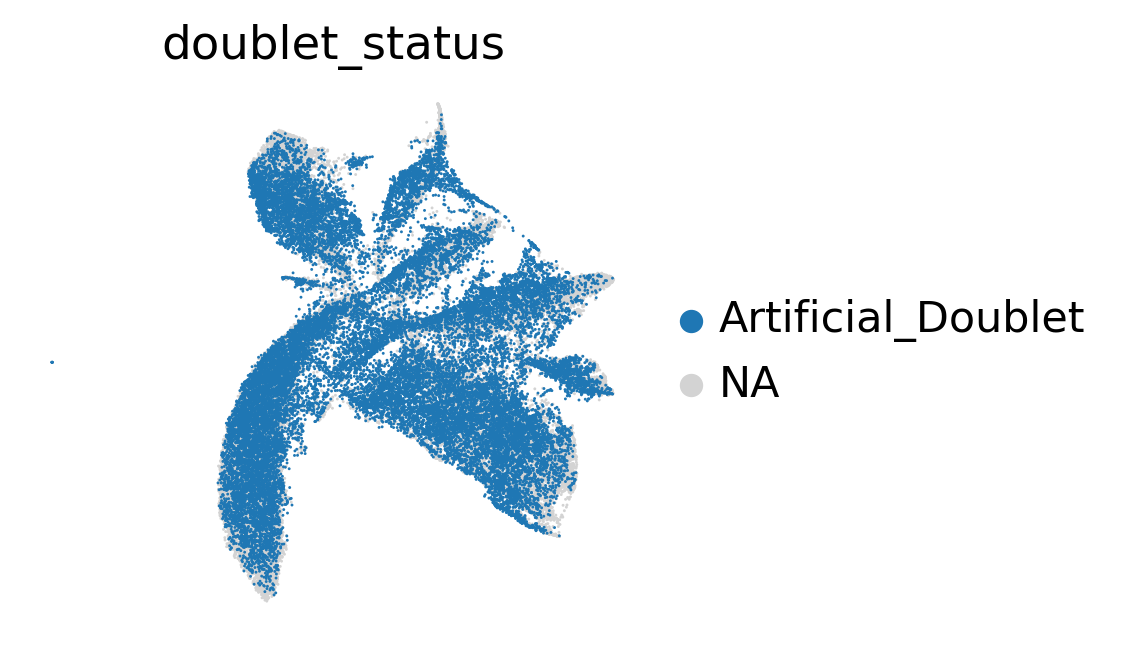

In [53]:
sc.pl.umap(adata_combined, color=f'doublet_status', alpha=1, size=3, frameon=False, palette=None, show=True, save=f'.{prefix}.adata_combined.color_by_simulated_doublet.pdf')

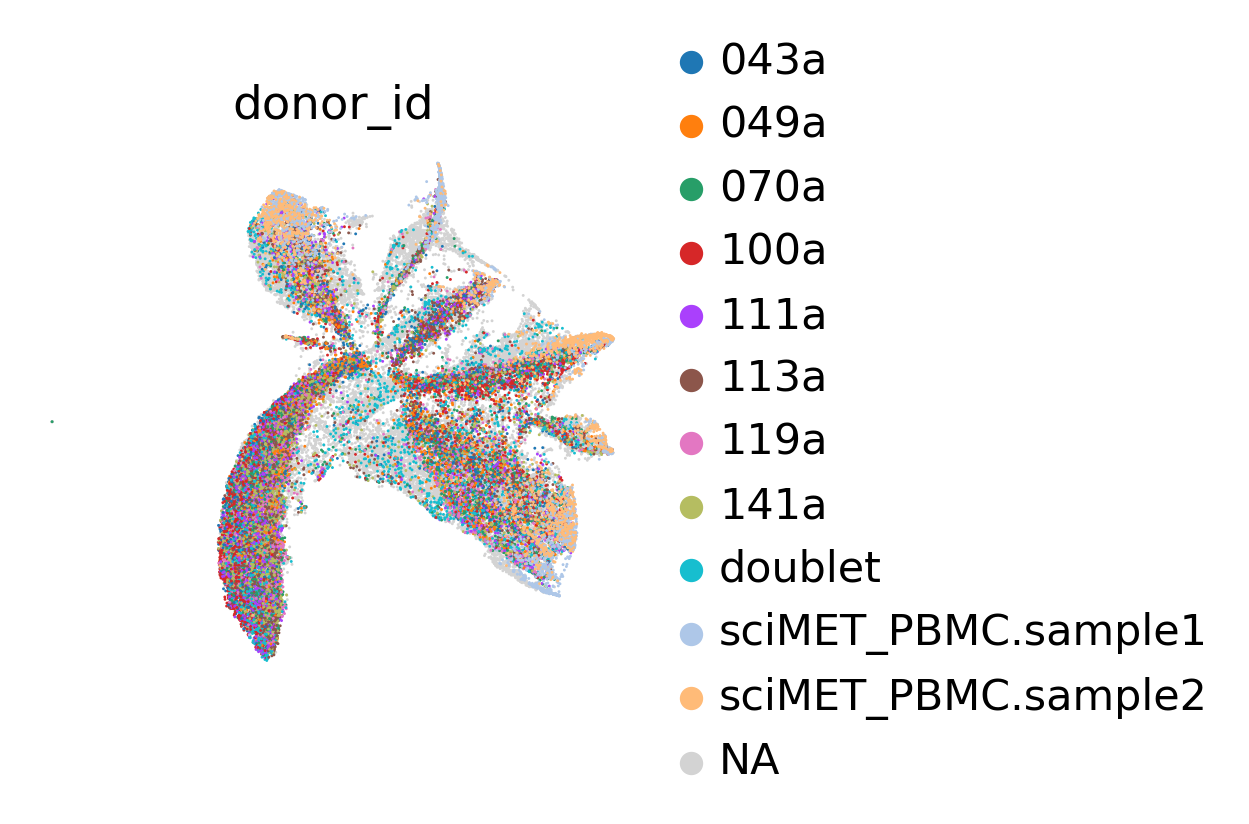

In [54]:
sc.pl.umap(adata_combined, color='donor_id', alpha=1, size=3, frameon=False, palette=None, show=True, save=f'.{prefix}.adata_combined.color_by_donor_id.pdf')

In [55]:
adata_file = 'adata/adata_combined_with_artificial_doublets.processed.h5ad'
adata_combined.write(adata_file)

In [56]:
# split PCA embeddings
X_pca = adata_combined.obsm["X_pca"]
X_real = X_pca[:n_obs]
X_doublets = X_pca[n_obs:]

In [57]:
import sys
sys.path.append('/data/leuven/357/vsc35706/notebook/sciMET/scripts/analysis')
from doublet_detection import *

In [58]:
n_cells = X_real.shape[0]
n_doublets = X_doublets.shape[0]
sim_ratio = n_doublets / n_cells
k_base = int(round(0.5 * np.sqrt(n_cells)))
k_adj = int(round(k_base * (1 + sim_ratio)))
print(f"Scrublet recommended k: {k_adj}")

Scrublet recommended k: 165


In [59]:
# compute doublet scores
doublet_scores_cells, doublet_scores_doublets = compute_doublet_scores(
    X_real,
    X_doublets,
    n_neighbors=k_adj
)

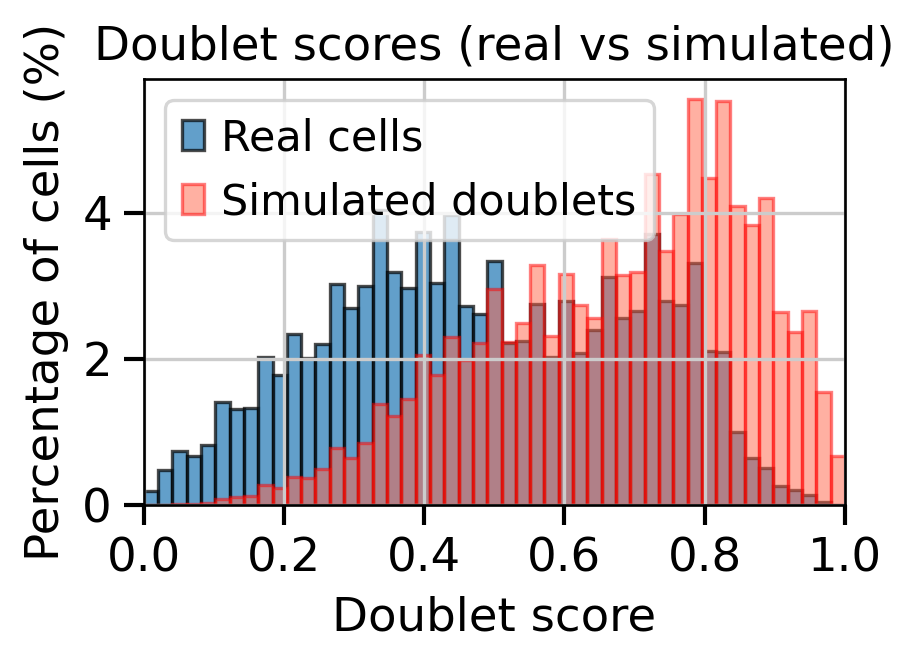

In [65]:
plt.figure(figsize=(4, 3))

bins = np.linspace(0, 1, 50)  # or use bins=50 for automatic binning

w_cells = np.ones_like(doublet_scores_cells) / len(doublet_scores_cells) * 100
w_doublets = np.ones_like(doublet_scores_doublets) / len(doublet_scores_doublets) * 100

plt.hist(doublet_scores_cells, bins=bins, weights=w_cells, alpha=0.7, edgecolor='black', label='Real cells')
plt.hist(doublet_scores_doublets, bins=bins, weights=w_doublets, alpha=0.5, color='tomato', edgecolor='red', label='Simulated doublets')

plt.xlabel('Doublet score')
plt.ylabel('Percentage of cells (%)')
plt.title('Doublet scores (real vs simulated)')
plt.legend()
plt.xlim([0,1])
plt.tight_layout()
plt.savefig('figures/doublet_score_hist.pdf', bbox_inches='tight')
plt.show()

In [66]:
# assign scores back to AnnData
adata_combined.obs["doublet_score"] = np.nan
adata_combined.obs.iloc[:n_obs, adata_combined.obs.columns.get_loc("doublet_score")] = doublet_scores_cells
adata_combined.obs.iloc[n_obs:, adata_combined.obs.columns.get_loc("doublet_score")] = doublet_scores_doublets

# scores for the real cells:
adata.obs["doublet_score"] = doublet_scores_cells
meta = adata.obs.copy()
meta.loc[meta['donor_id']=='doublet'].shape[0]

2419

In [69]:
# use percentile (e.g., top 10% as doublets)
threshold = adata.obs['doublet_score'].quantile(0.9)
print(f"Threshold (90th percentile): {threshold:.4f}")

Threshold (90th percentile): 0.7758


In [76]:
cutoff = 0.8
meta.loc[meta['doublet_score']>cutoff]['donor_id'].value_counts()

doublet                342
141a                   244
113a                   202
049a                   200
111a                   182
119a                   172
070a                   158
043a                   155
100a                   113
sciMET_PBMC.sample2     49
sciMET_PBMC.sample1     47
Name: donor_id, dtype: int64

In [83]:
col = f'doublet_score_exceeds_{cutoff}'
meta[col] = (meta['doublet_score'] > cutoff).astype(bool).astype(str)
meta[col] = meta['doublet_score'] > cutoff   # keep as bool
col = f'doublet_score_exceeds_{cutoff}'
n_doublets = meta[col].sum()
n_total = len(meta)
print(f"{n_doublets} / {n_total} cells called as doublets ({n_doublets / n_total * 100:.2f}%)")

1864 / 29741 cells called as doublets (6.27%)


In [92]:
mask_score = meta[col]                      # bool column (doublet_score > cutoff)
mask_donor = meta['donor_id'] == 'doublet'  # donor demultiplexing doublets

n_overlap = (mask_score & mask_donor).sum()
print(f"Overlap with heterogenic doublets: {n_overlap} cells")

Overlap with heterogenic doublets: 342 cells


In [104]:
mask_score

barcode
BC-GC169562.1A01.ATGAGTTC_AATACGCA_GAACCGCG     NaN
BC-GC169562.1A01.ATGAGTTC_CTTCGGCG_GAACCGCG     NaN
BC-GC169562.1A01.GGAGGCCT_AATACGCA_GAACCGCG     NaN
BC-GC169562.1A01.GTCTCCAG_TCGTAGGC_GAACCGCG     NaN
BC-GC169562.1A01.TCGAAGCG_TGGCCGGC_GAACCGCG     NaN
                                               ... 
PBMC.3H12.GCCGTCGCGT_CTTCGGCGCA_GCGTATAC        NaN
PBMC.3H12.GCCGTCGCGT_GGCAATGAGA_GCGTATAC        NaN
PBMC.3H12.GGAGGCCTCC_ACCGGAATTA_GCGTATAC       True
PBMC.3H12.GGAGGCCTCC_GGCAATGAGA_GCGTATAC        NaN
PBMC.3H12.TCGAAGCGCG_CTTCGGCGCA_GCGTATAC        NaN
Name: doublet_score_exceeds_0.8, Length: 29741, dtype: object

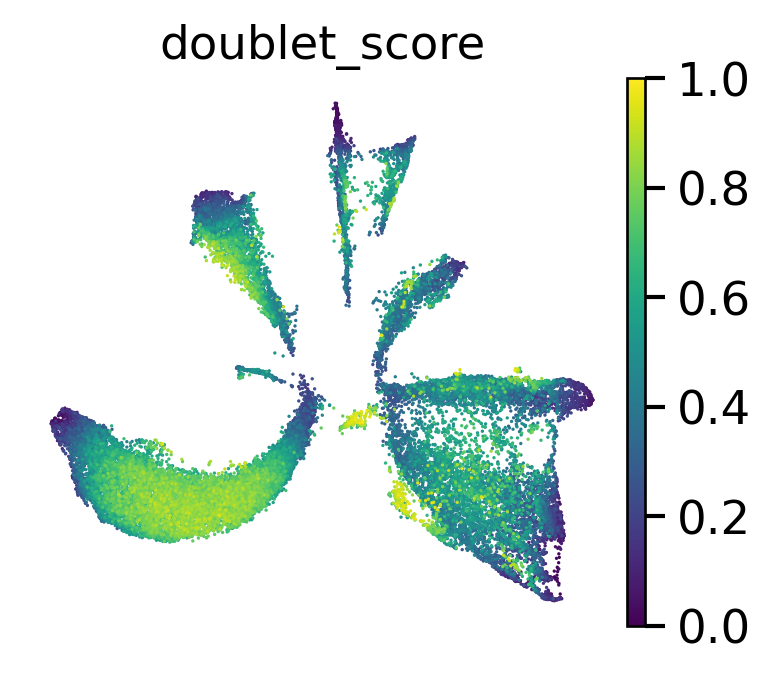

In [80]:
plt.rcParams['figure.figsize'] = (3.5,3)

sc.pl.umap(adata, color='doublet_score', alpha=alpha, frameon=False, vmin=0, vmax=1,
          save=f'.{prefix}.color_by_heterotypic_doublet_score.pdf'
          )

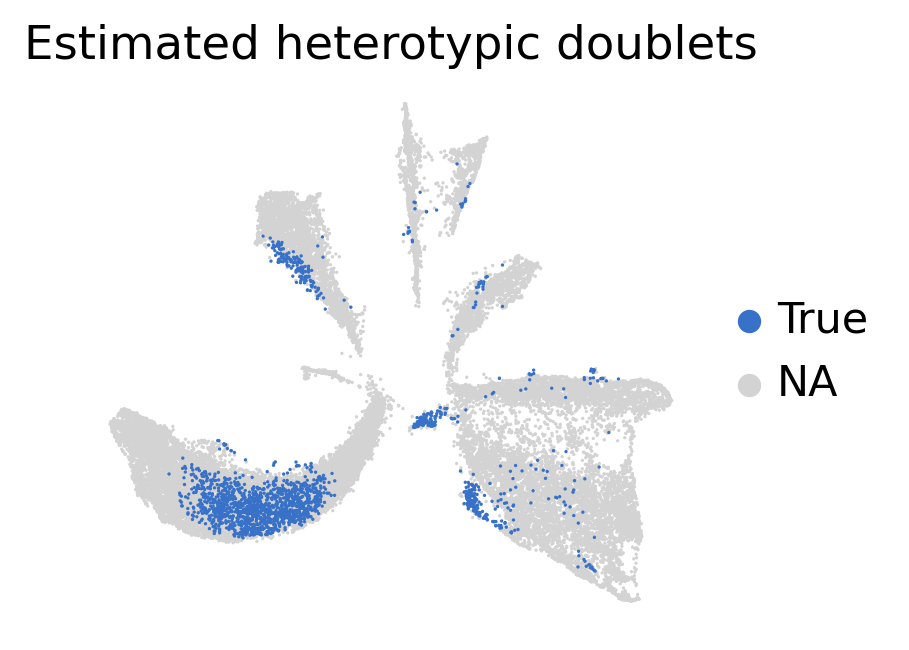

In [84]:
doublet_palette = {
    'True':'#3771C8', 
    'False':'lightgray'
}
cutoff=0.8
adata.obs[col] = (adata.obs['doublet_score'] > cutoff).astype(bool).astype(str)
adata.obs[col] = adata.obs[col].replace('False', np.nan)
sc.pl.umap(adata, color=col, alpha=1, #size=3, 
           frameon=False, 
           title="Estimated heterotypic doublets", palette=doublet_palette, 
           save=f'.{prefix}.color_by_heterotypic_doublet.pdf')

In [109]:
meta = adata.obs.copy()
mask_score   = meta[col] == 'True'
mask_donor   = meta['donor_id'] == 'doublet'
mask_cluster = adata.obs['doublet_cluster'] == 'True' 

mask_cluster = mask_cluster.reindex(meta.index)

n_neither = (~mask_score & ~mask_donor & ~mask_cluster).sum()
print(f"Called by none of the three groups of doublets: {n_neither} / {len(meta)} cells ({n_neither / len(meta) * 100:.2f}%)")

Called by none of the three groups of doublets: 25674 / 29741 cells (86.33%)


In [116]:
meta['keep'] = ~mask_score & ~mask_donor & ~mask_cluster
adata.obs['keep'] = ~mask_score & ~mask_donor & ~mask_cluster

## 💾 Save AnnData object

In [117]:
adata_file = 'adata/adata.debias_VMR.processed.h5ad'

In [118]:
# save AnnData object
adata.write(adata_file)